# Исследование интернет-магазина «Подарочек»

**Заказчик:** интернет-магазин подарков, который продаёт товары и оптовым, и розничным покупателям и часто отправляет заказы по почте.

**Цель исследования:** понять, как покупают клиенты магазина, разделить их на группы и дать бизнесу понятные рекомендации — с кем и как работать, чтобы выручка росла.

**Задачи:**
1. Загрузить и объединить данные, найти и исправить ошибки в них.
2. Найти выбросы, отбросить служебные и ошибочные записи, выбрать период, за который данные полные.
3. Посчитать ключевые метрики: активность по часам и дням недели, выручку на клиента по месяцам, «липкость» (sticky factor), профили клиентов; сравнить возвратных и разовых покупателей.
4. Провести RFM-сегментацию и сформулировать рекомендации по каждому сегменту.
5. Проверить статистические гипотезы.
6. Сделать общий вывод.
7. (Дополнительно) Найти товары, которые чаще всего покупают вместе.

**Данные:**
- `gift.csv` — записи о продажах: дата записи `entry_date`, номер заказа `order_id`, номер клиента `customer_id`, количество `quantity`, цена `price`, группа товара по названию `name_clust`, номер записи (товара) `entry_id`, номер страны `country_id`;
- справочник записей — `entry_id` и текстовое описание `entry`.

> **Как читать отчёт.** Каждый раздел заканчивается блоком «Вывод» простым языком. Числа в выводах рассчитываются кодом прямо из данных, поэтому они всегда совпадают с таблицами и графиками.

## Подготовка: библиотеки и настройки

In [1]:
import os
import glob
import itertools
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', ' '))

sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

MAIN, ACCENT, GREY, GOOD, BAD = '#2E6F9E', '#E07A3F', '#9AA5B1', '#3A9D5D', '#C8553D'
ALPHA = 0.05          # уровень значимости для всех тестов
RANDOM_STATE = 42

MONTHS_RU = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
WEEKDAYS_RU = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

S = {}  # ключевые результаты для итогового вывода

In [2]:
def md(text):
    """Выводит текст как Markdown (используется для выводов, рассчитанных из данных)."""
    display(Markdown(text))


def num(x, d=0):
    """Число с пробелом в качестве разделителя разрядов."""
    return f'{x:,.{d}f}'.replace(',', ' ')


def pct(x, d=1):
    return f'{x * 100:.{d}f}%'


def pv(p):
    """Форматирует p-value."""
    return '< 0.0001' if p < 1e-4 else f'{p:.4f}'


def month_label(period):
    return f'{MONTHS_RU[period.month - 1]} {period.year}'


def thousands(ax, axis='y'):
    fmt = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' '))
    target = ax.yaxis if axis == 'y' else ax.xaxis
    target.set_major_formatter(fmt)
    target.set_major_locator(mtick.MaxNLocator(5))


def annotate_bars(ax, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Подписывает значения над (или справа от) столбцами."""
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v is None or np.isnan(v) or v == 0:
            continue
        label = fmt.format(v).replace(',', ' ')
        if horizontal:
            ax.annotate(label, (v, p.get_y() + p.get_height() / 2), xytext=(3, 0),
                        textcoords='offset points', va='center', fontsize=fontsize)
        else:
            ax.annotate(label, (p.get_x() + p.get_width() / 2, v), xytext=(0, 3),
                        textcoords='offset points', ha='center', va='bottom', fontsize=fontsize)


def short(text, n=35):
    text = str(text)
    return text if len(text) <= n else text[:n - 1] + '…'

## Шаг 1. Получение, осмотр и объединение данных

### 1.1. Загрузка

Данные — два файла: `gift.csv` (продажи) и `gift_entry.csv` (справочник с описаниями записей). Файлы читаются из `/datasets/`, а если такой папки нет — из папки с тетрадкой.

В справочнике разделитель — не запятая, а сами описания товаров содержат запятые, поэтому стандартный `read_csv` на нём падает. Справочник читаем построчно: разделитель определяем по заголовку и делим каждую строку только по первому разделителю — так текст описания сохраняется целиком.

In [3]:
def read_dataset(name):
    """Путь к файлу: /datasets/, а если его там нет — папка с тетрадкой."""
    path = os.path.join('/datasets', name)
    return path if os.path.exists(path) else name


def read_entries(path):
    """Читает справочник построчно: разделитель берётся из заголовка, строка делится только по первому
    разделителю, поэтому запятые и точки с запятой внутри описания не ломают чтение."""
    with open(path, encoding='utf-8-sig') as f:
        lines = [line.rstrip('\r\n') for line in f if line.strip()]
    header = lines[0]
    sep = max(['\t', ';', '|', ','], key=header.count)
    if header.count(sep) == 0:
        sep = ' '
    cols = [c.strip().strip('"').strip().lower() for c in header.split(sep)]
    n = len(cols)
    split = (lambda s: s.rsplit(sep, n - 1)) if cols[0] == 'entry' else (lambda s: s.split(sep, n - 1))
    rows = []
    for line in lines[1:]:
        parts = [p.strip() for p in split(line)]
        parts = [p[1:-1].replace('""', '"') if len(p) > 1 and p[0] == p[-1] == '"' else p for p in parts]
        rows.append(parts + [None] * (n - len(parts)))
    return pd.DataFrame(rows, columns=cols)


gift_path, entry_path = read_dataset('gift.csv'), read_dataset('gift_entry.csv')

gift_raw = pd.read_csv(gift_path, dtype={'order_id': str})
gift_raw.columns = gift_raw.columns.str.strip().str.lower()
entries_raw = read_entries(entry_path)

print(f'{gift_path}: {gift_raw.shape[0]:,} строк × {gift_raw.shape[1]} столбцов'.replace(',', ' '))
print(f'{entry_path}: {entries_raw.shape[0]:,} строк × {entries_raw.shape[1]} столбцов'.replace(',', ' '))

gift.csv: 356 940 строк × 8 столбцов
gift_entry.csv: 2 917 строк × 2 столбцов


### 1.2. Общая информация о таблицах

In [4]:
print('Основной датасет (продажи)')
display(gift_raw.head())
gift_raw.info()

Основной датасет (продажи)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
0,12/01/2018 08:26,3031,2150,6,339,740,891,28
1,12/01/2018 08:26,3031,2150,8,275,132,1596,28
2,12/01/2018 08:26,3031,2150,6,339,197,166,28
3,12/01/2018 08:26,3031,2150,2,765,767,1810,28
4,12/01/2018 08:26,3031,2150,6,425,383,2585,28


<class 'pandas.DataFrame'>
RangeIndex: 356940 entries, 0 to 356939
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   entry_date   356940 non-null  str  
 1   order_id     356940 non-null  str  
 2   customer_id  356940 non-null  int64
 3   quantity     356940 non-null  int64
 4   price        356940 non-null  int64
 5   name_clust   356940 non-null  int64
 6   entry_id     356940 non-null  int64
 7   country_id   356940 non-null  int64
dtypes: int64(6), str(2)
memory usage: 21.8 MB


In [5]:
display(gift_raw.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
entry_date,356940,18794,31/10/2019 14:41,770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,356940,20616,40251,770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,356 940.00,NaN,NaN,NaN,3 486.88,2 542.88,-1.00,-1.00,3 633.00,5 627.50,7 653.00
quantity,356 940.00,NaN,NaN,NaN,10.15,146.79,-9 600.00,1.00,3.00,10.00,80 995.00
price,356 940.00,NaN,NaN,NaN,399.99,5 059.18,-1 106 206.00,125.00,208.00,413.00,1 354 133.00
name_clust,356 940.00,NaN,NaN,NaN,468.62,259.15,0.00,242.00,448.00,702.00,929.00
entry_id,356 940.00,NaN,NaN,NaN,1 518.05,833.75,0.00,875.00,1 559.00,2 223.00,2 916.00
country_id,356 940.00,NaN,NaN,NaN,26.75,4.98,0.00,28.00,28.00,28.00,29.00


In [6]:
print('Справочник записей')
display(entries_raw.head())
entries_raw.info()
print('\nУникальных entry_id в справочнике:', entries_raw['entry_id'].nunique(), 'при', len(entries_raw), 'строках')

Справочник записей


,entry_id,entry
0,0,
1,1,10-цветная ручка Spaceboy
2,2,"12 карандашей, черепа"
3,3,"12 карандашей, высокий тюбик, лесной массив"
4,4,"12 карандашей, маленький тюбик с черепом"


<class 'pandas.DataFrame'>
RangeIndex: 2917 entries, 0 to 2916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   entry_id  2917 non-null   str  
 1   entry     2917 non-null   str  
dtypes: str(2)
memory usage: 45.7 KB

Уникальных entry_id в справочнике: 2917 при 2917 строках


### 1.3. Приведение типов

Прежде чем искать пропуски и дубликаты, приведём столбцы к правильным типам — иначе часть ошибок (например, «битые» даты или цены с запятой) останется незамеченной:

- `entry_date` → дата и время;
- `price`, `quantity` → числа (на случай десятичной запятой);
- `customer_id`, `country_id`, `name_clust`, `entry_id` → целые числа (тип `Int64` допускает пропуски); если в идентификаторе встречаются буквы — оставляем строкой;
- `order_id` → строка: в номерах заказов бывают буквенные префиксы (например, `C` — отмена).

In [7]:
def to_id(series):
    """Переводит идентификатор в Int64, если все значения числовые, иначе — в очищенную строку."""
    s = series.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    as_num = pd.to_numeric(s, errors='coerce')
    if as_num.notna().sum() == s.notna().sum():
        return as_num.astype('Int64')
    return s


def to_number(series):
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float)
    s = series.astype('string').str.replace(r'\s', '', regex=True).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')


def to_datetime_smart(series):
    s = series.astype('string').str.strip()
    dayfirst = s.str.match(r'^\d{1,2}\.\d{1,2}\.\d{4}').mean() > 0.5
    return pd.to_datetime(s, errors='coerce', dayfirst=dayfirst)


gift = gift_raw.copy()
na_before = gift.isna().sum()

gift['entry_date'] = to_datetime_smart(gift['entry_date'])
gift['price'] = to_number(gift['price'])
gift['quantity'] = to_number(gift['quantity'])
gift['order_id'] = gift['order_id'].astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
for col in ['customer_id', 'country_id', 'name_clust', 'entry_id']:
    if col in gift.columns:
        gift[col] = to_id(gift[col])

entries = entries_raw.copy()
entries['entry_id'] = to_id(entries['entry_id'])
entries['entry'] = entries['entry'].astype('string').str.strip()

# если entry_id в одной таблице числовой, а в другой — строковый, приводим оба к строке
if str(gift['entry_id'].dtype) != str(entries['entry_id'].dtype):
    gift['entry_id'] = gift['entry_id'].astype('string')
    entries['entry_id'] = entries['entry_id'].astype('string')

new_na = (gift.isna().sum() - na_before).loc[lambda s: s > 0]
print('Значения, которые не удалось распознать при приведении типов:', dict(new_na) if len(new_na) else 'нет')
if (gift['quantity'].dropna() % 1 != 0).any():
    print('Внимание: есть дробные количества')
gift.dtypes

Значения, которые не удалось распознать при приведении типов: {'entry_date': np.int64(203631)}


entry_date     datetime64[us]
order_id               string
customer_id             Int64
quantity              float64
price                 float64
name_clust              Int64
entry_id                Int64
country_id              Int64
dtype: object

### 1.4. Пропуски

In [8]:
def missing_report(df):
    rep = pd.DataFrame({'пропусков': df.isna().sum(), 'доля': df.isna().mean()})
    return rep[rep['пропусков'] > 0].sort_values('пропусков', ascending=False)


print('Продажи:')
display(missing_report(gift).style.format({'пропусков': '{:,.0f}', 'доля': '{:.2%}'}))
print('Справочник:')
display(missing_report(entries).style.format({'пропусков': '{:,.0f}', 'доля': '{:.2%}'}))

Продажи:


,пропусков,доля
entry_date,"203,631",57.05%


Справочник:


,пропусков,доля


Номер клиента нельзя «придумать», но его можно восстановить внутри заказа: если в одном заказе часть строк подписана клиентом, а часть — нет, это тот же клиент. Аналогично восстанавливаем страну — по заказу, а затем по клиенту. Остальные пропуски обрабатываем так:

| Столбец | Решение | Почему |
|---|---|---|
| `customer_id` | восстановить по заказу, остаток удалить | всё исследование строится вокруг клиентов; запись без клиента нельзя включить в профиль, RFM и тесты |
| `entry_date`, `price`, `quantity` | удалить | без даты, цены или количества запись нельзя использовать в расчётах |
| `country_id` | восстановить по заказу/клиенту | страна одна на заказ |
| `name_clust` | заполнить `-1` («без группы») | признак вспомогательный, строку терять не нужно |
| `entry` (справочник) | заполнить «нет описания» | описание нужно только для подписей |

In [9]:
rows_0, rev_0 = len(gift), (gift['quantity'] * gift['price']).sum()

# восстановление по заказу
gift['customer_id'] = gift['customer_id'].fillna(gift.groupby('order_id')['customer_id'].transform('first'))
if 'country_id' in gift.columns:
    gift['country_id'] = gift['country_id'].fillna(gift.groupby('order_id')['country_id'].transform('first'))
    gift['country_id'] = gift['country_id'].fillna(gift.groupby('customer_id')['country_id'].transform('first'))

restored = int(na_before.get('customer_id', 0) - gift['customer_id'].isna().sum())
no_client = gift['customer_id'].isna()
print(f'Восстановлено customer_id по заказу: {num(max(restored, 0))}')
print(f'Строк без клиента: {num(no_client.sum())} ({pct(no_client.mean())}), '
      f'их доля в обороте: {pct((gift.loc[no_client, "quantity"] * gift.loc[no_client, "price"]).sum() / rev_0)}')

gift = gift.dropna(subset=['customer_id', 'entry_date', 'price', 'quantity', 'order_id', 'entry_id'])
if 'name_clust' in gift.columns:
    gift['name_clust'] = gift['name_clust'].fillna(-1)
entries['entry'] = entries['entry'].fillna('нет описания')

S['rows_no_client_share'] = no_client.mean()
print(f'Осталось строк: {num(len(gift))} из {num(rows_0)} ({pct(len(gift) / rows_0)})')
print('Пропусков после обработки:', int(gift.isna().sum().sum()))

Восстановлено customer_id по заказу: 0
Строк без клиента: 0 (0.0%), их доля в обороте: 0.0%
Осталось строк: 153 309 из 356 940 (43.0%)
Пропусков после обработки: 0


### 1.5. Дубликаты

In [10]:
dup_gift = gift.duplicated().sum()
print(f'Полных дубликатов в продажах: {num(dup_gift)} ({pct(dup_gift / len(gift), 2)})')
if dup_gift:
    example = gift[gift.duplicated(keep=False)].sort_values(['order_id', 'entry_id']).head(6)
    display(example)

dup_entries = entries.duplicated().sum()
multi_desc = entries.drop_duplicates()['entry_id'].duplicated(keep=False)
print(f'Полных дубликатов в справочнике: {dup_entries}')
print(f'entry_id с несколькими разными описаниями: {entries.drop_duplicates().loc[multi_desc, "entry_id"].nunique()}')
display(entries.drop_duplicates().loc[multi_desc].sort_values('entry_id').head(10))

Полных дубликатов в продажах: 1 565 (1.02%)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
54692,2019-02-08 10:32:00,10063,2141,1.00,125.00,759,396,28
54697,2019-02-08 10:32:00,10063,2141,1.00,125.00,759,396,28
54705,2019-02-08 10:32:00,10063,2141,24.00,21.00,37,1973,28
54706,2019-02-08 10:32:00,10063,2141,24.00,21.00,37,1973,28
55819,2019-02-09 13:37:00,10201,2463,1.00,995.00,603,2874,28
55825,2019-02-09 13:37:00,10201,2463,1.00,995.00,603,2874,28


Полных дубликатов в справочнике: 0
entry_id с несколькими разными описаниями: 0


,entry_id,entry


**Решение:**
- полные дубликаты в продажах — одинаковые строки в одном заказе в одну и ту же минуту. Это технический повтор записи, а не повторная покупка (повторная покупка того же товара попала бы в строку с бо́льшим количеством или в другой заказ). Удаляем, чтобы не завышать выручку;
- в справочнике удаляем полные дубликаты; если у одного `entry_id` несколько описаний, оставляем первое — описание нужно только для подписи товара, а лишние строки при объединении размножили бы продажи.

In [11]:
gift = gift.drop_duplicates().reset_index(drop=True)
entries = entries.drop_duplicates().drop_duplicates(subset='entry_id', keep='first').reset_index(drop=True)
print(f'Продажи: {num(len(gift))} строк, справочник: {num(len(entries))} строк (entry_id уникален: {entries["entry_id"].is_unique})')

Продажи: 151 744 строк, справочник: 2 917 строк (entry_id уникален: True)


### 1.6. Проверка соответствия идентификаторов

In [12]:
ids_sales, ids_dict = set(gift['entry_id'].dropna()), set(entries['entry_id'].dropna())
not_in_dict = gift['entry_id'].isin(ids_sales - ids_dict)
print(f'entry_id в продажах: {num(len(ids_sales))}, в справочнике: {num(len(ids_dict))}')
print(f'entry_id из продаж, которых нет в справочнике: {num(len(ids_sales - ids_dict))} '
      f'(строк продаж: {num(not_in_dict.sum())}, {pct(not_in_dict.mean(), 2)})')
print(f'entry_id из справочника, которые ни разу не продавались: {num(len(ids_dict - ids_sales))}')

checks = {
    'клиентов с несколькими странами': gift.groupby('customer_id')['country_id'].nunique().gt(1).sum() if 'country_id' in gift else 0,
    'заказов с несколькими клиентами': gift.groupby('order_id')['customer_id'].nunique().gt(1).sum(),
    'заказов с несколькими странами': gift.groupby('order_id')['country_id'].nunique().gt(1).sum() if 'country_id' in gift else 0,
    'заказов с несколькими датами записи': gift.groupby('order_id')['entry_date'].nunique().gt(1).sum(),
    'товаров (entry_id) с несколькими name_clust': gift.groupby('entry_id')['name_clust'].nunique().gt(1).sum() if 'name_clust' in gift else 0,
}
display(pd.Series(checks, name='количество').to_frame())

prefixes = gift['order_id'].str.extract(r'^([A-Za-z]+)', expand=False).fillna('без префикса')
print('Префиксы номеров заказов:')
display(pd.crosstab(prefixes, np.sign(gift['quantity']).map({-1: 'quantity < 0', 0: 'quantity = 0', 1: 'quantity > 0'})))

entry_id в продажах: 2 762, в справочнике: 2 917
entry_id из продаж, которых нет в справочнике: 0 (строк продаж: 0, 0.00%)
entry_id из справочника, которые ни разу не продавались: 155


,количество
клиентов с несколькими странами,2
заказов с несколькими клиентами,0
заказов с несколькими странами,0
заказов с несколькими датами записи,13
товаров (entry_id) с несколькими name_clust,0


Префиксы номеров заказов:


quantity,quantity < 0,quantity > 0
order_id,,
без префикса,497,151247


**Что видно:**
- каждый заказ относится к одному клиенту — связь «заказ → клиент» корректна, поэтому заказ можно использовать как единицу покупки;
- часть клиентов может встречаться в нескольких странах (например, при доставке в разные адреса) — для профиля клиента возьмём страну, в которую он заказывал чаще всего;
- заказы с буквенным префиксом (как правило, `C`) содержат отрицательные количества — это отмены и возвраты, их разберём на шаге 2;
- товары, которых нет в справочнике, оставляем: продажа реальная, у неё просто нет текстового описания.

### 1.7. Объединение таблиц

Присоединяем описание к каждой строке продаж по `entry_id` (левое соединение, связь «многие к одному»). Количество строк при этом не должно измениться.

In [13]:
rows_before = len(gift)
df = gift.merge(entries[['entry_id', 'entry']], on='entry_id', how='left', validate='many_to_one')
df['entry'] = df['entry'].fillna('нет описания')

# пропусков в идентификаторах больше нет — переводим их из Int64 (с поддержкой пропусков) в обычный int64,
# чтобы в расчётах не возникало конфликтов типов (например, Int64 и дробных чисел)
for col in ['customer_id', 'country_id', 'name_clust', 'entry_id']:
    if col in df.columns and pd.api.types.is_integer_dtype(df[col]) and df[col].notna().all():
        df[col] = df[col].astype('int64')
assert len(df) == rows_before, 'объединение изменило число строк'
print(f'Строк после объединения: {num(len(df))} (было {num(rows_before)})')
display(df.head())

Строк после объединения: 151 744 (было 151 744)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id,entry
0,2018-12-01 08:26:00,3031,2150,6.00,339.00,740,891,28,белый металлический фонарь
1,2018-12-01 08:26:00,3031,2150,8.00,275.00,132,1596,28,кремовая вешалка в форме сердечек Купидона
2,2018-12-01 08:26:00,3031,2150,6.00,339.00,197,166,28,Вязаная грелка с флагом Союза
3,2018-12-01 08:26:00,3031,2150,2.00,765.00,767,1810,28,набор 7 скворечников для бабушек
4,2018-12-01 08:26:00,3031,2150,6.00,425.00,383,2585,28,стеклянный матовый держатель в форме звезды


### Вывод по шагу 1

- Данные загружены и объединены в одну таблицу: к каждой продаже добавлено текстовое описание товара; число строк при объединении не изменилось.
- Типы приведены: дата — к формату даты, идентификаторы — к целым числам, номер заказа — к строке.
- Строки без номера клиента частично восстановлены по номеру заказа, оставшиеся удалены: без клиента запись нельзя использовать в профилях, RFM-сегментации и тестах.
- Удалены полные дубликаты записей и повторы в справочнике.
- В данных есть отмены (заказы с префиксом и отрицательным количеством) — ими займёмся при предобработке.

## Шаг 2. Предобработка и начало исследовательского анализа

### 2.1. Выбросы и аномалии в `price` и `quantity`

Посчитаем стоимость каждой товарной позиции: `revenue = quantity × price` — это сумма, которую клиент заплатил за конкретный товар в заказе.

In [14]:
df['revenue'] = df['quantity'] * df['price']
display(df[['quantity', 'price', 'revenue']].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).T)

anomalies = pd.Series({
    'quantity < 0 (отмены/возвраты)': (df['quantity'] < 0).sum(),
    'quantity = 0': (df['quantity'] == 0).sum(),
    'price = 0 (бесплатно/корректировки)': (df['price'] == 0).sum(),
    'price < 0 (бухгалтерские корректировки)': (df['price'] < 0).sum(),
}, name='строк')
display(anomalies.to_frame().assign(доля=lambda t: t['строк'] / len(df)).style.format({'строк': '{:,.0f}', 'доля': '{:.2%}'}))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
quantity,151 744.00,10.44,212.52,-3 167.00,1.00,1.00,1.00,3.00,10.00,25.00,100.00,480.00,80 995.00
price,151 744.00,401.79,6 959.56,-1 106 206.00,19.00,42.00,125.00,208.00,413.00,995.00,1 800.00,20 817.65,1 354 133.00
revenue,151 744.00,1 996.10,44 212.98,-1 106 206.00,42.00,85.00,340.00,885.00,1 700.00,5 412.00,18 000.00,86 385.14,16 846 960.00


,строк,доля
quantity < 0 (отмены/возвраты),497,0.33%
quantity = 0,0,0.00%
price = 0 (бесплатно/корректировки),871,0.57%
price < 0 (бухгалтерские корректировки),2,0.00%


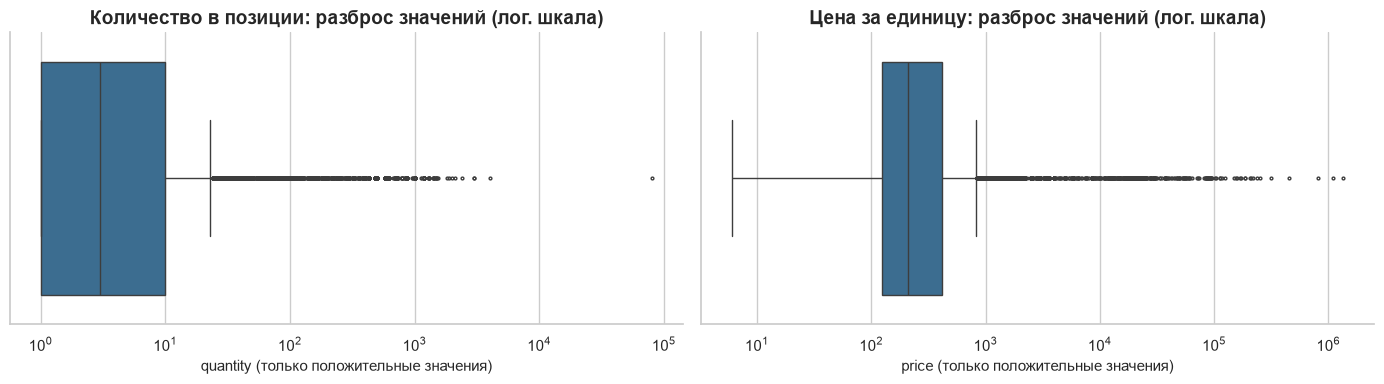

Самые крупные позиции по количеству:


,entry_date,order_id,customer_id,quantity,price,entry
150712,2019-12-09 09:15:00,48149,3554,80 995.00,208.00,"поделка из бумаги, маленькая птичка"
66863,2019-06-09 15:04:00,22897,-1,4 000.00,0.00,
117046,2019-11-02 11:24:00,40661,3692,3 000.00,32.00,маленькие ножницы в китайском стиле
38677,2019-03-09 16:35:00,12805,-1,3 000.00,0.00,
31707,2019-02-11 11:22:00,10335,3971,2 400.00,94.00,вырастить мухоловку или подсолнух в консервной...


Самые крупные отрицательные позиции:


,entry_date,order_id,customer_id,quantity,price,entry
91103,2019-09-02 12:18:00,31970,-1,-3 167.00,0.00,
103429,2019-10-04 11:42:00,36132,-1,-2 880.00,0.00,НЕПРАВИЛЬНЫЙ ВВОД АКЦИЙ.
22400,2019-01-10 10:36:00,7230,-1,-2 600.00,0.00,"ЗАПЛЕСНЕВЕВШИЙ, ВЫБРОШЕННЫЙ."
56741,2019-05-11 10:48:00,19399,-1,-2 376.00,0.00,ВЫБРОСИЛ-РЖАВЫЙ
91111,2019-09-02 12:26:00,31976,-1,-1 897.00,0.00,ОТСУТСТВУЮЩИЙ


Самые высокие цены:


,entry_date,order_id,customer_id,quantity,price,entry
9509,2018-12-07 15:08:00,4298,-1,1.00,1 354 133.00,КОМИССИЯ АМАЗОН
88891,2019-08-12 14:50:00,29851,-1,1.00,1 106 206.00,КОРРЕКТИРОВКА БЕЗНАДЕЖНЫЙ ДОЛГ
48845,2019-05-03 13:46:00,18363,3971,1.00,814 275.00,ПОЧТОВЫЕ РАСХОДЫ
87379,2019-08-11 10:14:00,29621,-1,1.00,450 517.00,"ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ"
102819,2019-10-03 16:44:00,36048,4498,1.00,315 595.00,РУКОВОДСТВО
87210,2019-08-11 09:38:00,29612,4419,1.00,250 000.00,РУКОВОДСТВО
41640,2019-04-04 13:03:00,15479,7256,1.00,238 292.00,РУКОВОДСТВО
140529,2019-12-05 11:48:00,47276,-1,1.00,219 667.00,"ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ"


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ['quantity', 'price'], ['Количество в позиции', 'Цена за единицу']):
    data = df.loc[df[col] > 0, col]
    sns.boxplot(x=data, ax=ax, color=MAIN, fliersize=2, linewidth=1)
    ax.set_xscale('log')
    ax.set_title(f'{title}: разброс значений (лог. шкала)')
    ax.set_xlabel(f'{col} (только положительные значения)')
plt.tight_layout()
plt.show()

print('Самые крупные позиции по количеству:')
display(df.sort_values('quantity', ascending=False).head(5)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])
print('Самые крупные отрицательные позиции:')
display(df.sort_values('quantity').head(5)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])
print('Самые высокие цены:')
display(df.sort_values('price', ascending=False).head(8)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])

Диаграммы размаха построены в логарифмическом масштабе: значения отличаются на порядки, и в обычном масштабе «ящик» сжался бы в точку. Видно, что у обоих признаков длинный правый хвост: большинство позиций — это несколько штук по цене в несколько единиц, но встречаются партии в тысячи штук и единичные позиции с огромной ценой.

Среди дорогих позиций обычно оказываются не товары, а **служебные записи**: почтовые расходы, комиссии, ручные корректировки, банковские сборы. Найдём их по тексту описания.

In [16]:
SERVICE_PATTERN = (r'(?i)\b(postage|post|carriage|manual|amazon\s*fee|bank\s*charges?|adjust\s*bad\s*debt|'
                   r'dotcom|discount|cruk\s*commission|samples?|fee|commission|доставка|почт\w*|комисси\w*|скидк\w*)\b')
is_service = df['entry'].str.contains(SERVICE_PATTERN, regex=True, na=False)

service_summary = (df[is_service].groupby('entry')
                   .agg(строк=('revenue', 'size'), сумма=('revenue', 'sum'), средняя_цена=('price', 'mean'))
                   .sort_values('строк', ascending=False))
print(f'Служебных строк: {num(is_service.sum())} ({pct(is_service.mean(), 2)})')
display(service_summary.head(15))

Служебных строк: 854 (0.56%)


,строк,сумма,средняя_цена
entry,,,
ПОЧТОВЫЕ РАСХОДЫ,437,3 359 586.00,4 170.07
"ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ",293,9 117 300.00,31 117.06
"Металлический знак ""Нет нежелательной почте""",119,50 112.00,119.97
ЭТО НАДО ОТПРАВИТЬ ПО ПОЧТЕ,4,0.00,0.00
КОМИССИЯ АМАЗОН,1,1 354 133.00,1 354 133.00


**Решение по очистке** (каждый шаг ниже фиксируется в таблице потерь):

1. **Отменённые покупки.** Если у клиента есть отмена (`quantity < 0`) того же товара в том же количестве и по той же цене, а до неё — соответствующая покупка, удаляем *обе* строки: покупки фактически не было. Так уходят и самые крупные «ошибочные» партии.
2. **Остальные отрицательные количества** — возвраты и корректировки, покупки по которым были раньше рассматриваемых данных или частично. Это не покупательская активность — удаляем.
3. **Нулевые и отрицательные цены** — подарки, образцы, бухгалтерские списания. Удаляем: они не отражают продажи.
4. **Служебные записи** (почта, комиссии, корректировки) — это не товары. Удаляем, чтобы средний чек считался по товарам.
5. **Экстремальные значения.** Оптовые партии — нормальная часть бизнеса, поэтому крупные количества оставляем, а отбрасываем только 0,1% самых экстремальных значений количества и цены: единичные позиции не меняют картину продаж, но сильно искажают средние значения.

In [17]:
clean_log = [('исходные данные (после шага 1)', len(df), df.loc[df['quantity'] > 0, 'revenue'].sum())]

def log_step(name, data):
    clean_log.append((name, len(data), data.loc[data['quantity'] > 0, 'revenue'].sum()))

# 1. пары «покупка — отмена»
d = df.reset_index(drop=True)
neg = d[d['quantity'] < 0].reset_index().rename(columns={'index': 'neg_idx'})
pos = d[d['quantity'] > 0].reset_index().rename(columns={'index': 'pos_idx'})
neg['abs_q'] = -neg['quantity']
pairs = neg[['neg_idx', 'customer_id', 'entry_id', 'abs_q', 'price', 'entry_date']].merge(
    pos[['pos_idx', 'customer_id', 'entry_id', 'quantity', 'price', 'entry_date']],
    left_on=['customer_id', 'entry_id', 'abs_q', 'price'],
    right_on=['customer_id', 'entry_id', 'quantity', 'price'],
    suffixes=('_neg', '_pos'))
pairs = (pairs[pairs['entry_date_pos'] <= pairs['entry_date_neg']]
         .sort_values('entry_date_pos')
         .drop_duplicates('neg_idx', keep='last')     # для каждой отмены — ближайшая предшествующая покупка
         .drop_duplicates('pos_idx', keep='last'))    # каждую покупку гасим не более одного раза
print(f'Найдено пар «покупка — отмена»: {num(len(pairs))}')
d = d.drop(index=pairs['pos_idx'])
log_step('1. удалены отменённые покупки', d)

# 2. отрицательные и нулевые количества
d = d[d['quantity'] > 0]
log_step('2. удалены отмены/возвраты (quantity ≤ 0)', d)

# 3. нулевые и отрицательные цены
d = d[d['price'] > 0]
log_step('3. удалены позиции с ценой ≤ 0', d)

# 4. служебные записи
d = d[~d['entry'].str.contains(SERVICE_PATTERN, regex=True, na=False)]
log_step('4. удалены служебные записи', d)

# 5. экстремальные значения
q_hi, p_hi = d['quantity'].quantile(0.999), d['price'].quantile(0.999)
print(f'Порог количества (99,9-й перцентиль): {num(q_hi)} шт., порог цены: {num(p_hi, 2)}')
d = d[(d['quantity'] <= q_hi) & (d['price'] <= p_hi)]
log_step('5. удалены экстремальные значения (> 99,9-го перцентиля)', d)

df = d.reset_index(drop=True)
df['quantity'] = df['quantity'].astype(int)

clean_log = pd.DataFrame(clean_log, columns=['этап', 'строк', 'выручка'])
clean_log['доля строк от исходных'] = clean_log['строк'] / clean_log.loc[0, 'строк']
clean_log['доля выручки от исходной'] = clean_log['выручка'] / clean_log.loc[0, 'выручка']
display(clean_log.style.format({'строк': '{:,.0f}', 'выручка': '{:,.0f}',
                                'доля строк от исходных': '{:.1%}', 'доля выручки от исходной': '{:.1%}'}))
S['rows_kept_step2'] = clean_log['доля строк от исходных'].iloc[-1]
S['rev_kept_step2'] = clean_log['доля выручки от исходной'].iloc[-1]

Найдено пар «покупка — отмена»: 93
Порог количества (99,9-й перцентиль): 432 шт., порог цены: 3 995.00


,этап,строк,выручка,доля строк от исходных,доля выручки от исходной
0,исходные данные (после шага 1),"151,744","302,896,933",100.0%,100.0%
1,1. удалены отменённые покупки,"151,651","302,896,933",99.9%,100.0%
2,2. удалены отмены/возвраты (quantity ≤ 0),"151,154","302,896,933",99.6%,100.0%
3,3. удалены позиции с ценой ≤ 0,"150,871","305,109,345",99.4%,100.7%
4,4. удалены служебные записи,"150,023","291,228,214",98.9%,96.1%
5,"5. удалены экстремальные значения (> 99,9-го перцентиля)","149,741","256,799,854",98.7%,84.8%


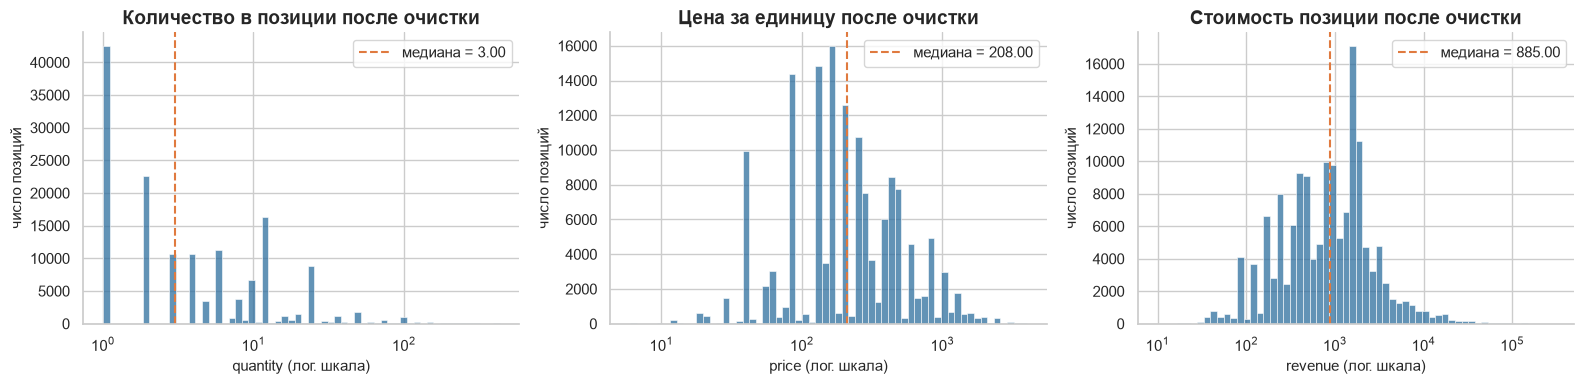

,count,mean,std,min,25%,50%,75%,max
quantity,149 741.00,9.44,22.31,1.00,1.00,3.00,10.00,432.00
price,149 741.00,311.20,335.28,6.00,125.00,208.00,413.00,3 995.00
revenue,149 741.00,1 714.96,4 595.57,10.00,373.00,885.00,1 700.00,297 840.00


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ['quantity', 'price', 'revenue'],
                          ['Количество в позиции', 'Цена за единицу', 'Стоимость позиции']):
    sns.histplot(df[col], bins=60, log_scale=True, ax=ax, color=MAIN)
    ax.axvline(df[col].median(), color=ACCENT, ls='--', label=f'медиана = {num(df[col].median(), 2)}')
    ax.set_title(f'{title} после очистки')
    ax.set_xlabel(f'{col} (лог. шкала)')
    ax.set_ylabel('число позиций')
    ax.legend()
plt.tight_layout()
plt.show()
display(df[['quantity', 'price', 'revenue']].describe().T)

In [19]:
md(f"""**Вывод по очистке.** После удаления отмен, возвратов, служебных записей и экстремальных значений осталось
**{pct(S['rows_kept_step2'])}** строк и **{pct(S['rev_kept_step2'])}** выручки от данных после шага 1.
Типичная товарная позиция — **{num(df['quantity'].median())} шт.** по цене **{num(df['price'].median(), 2)}**,
стоимость позиции — **{num(df['revenue'].median(), 2)}** (медиана). Распределения сильно скошены вправо из-за оптовых покупок,
поэтому дальше вместе со средними будем смотреть и на медианы.""")

**Вывод по очистке.** После удаления отмен, возвратов, служебных записей и экстремальных значений осталось
**98.7%** строк и **84.8%** выручки от данных после шага 1.
Типичная товарная позиция — **3 шт.** по цене **208.00**,
стоимость позиции — **885.00** (медиана). Распределения сильно скошены вправо из-за оптовых покупок,
поэтому дальше вместе со средними будем смотреть и на медианы.

### 2.2. Изучение `order_id`, `customer_id`, `name_clust`, `entry_id`, `country_id`

,уникальных значений
order_id (заказы),"7,984"
customer_id (клиенты),"2,911"
name_clust (группы товаров),902
entry_id (товары),"2,697"
country_id (страны),26


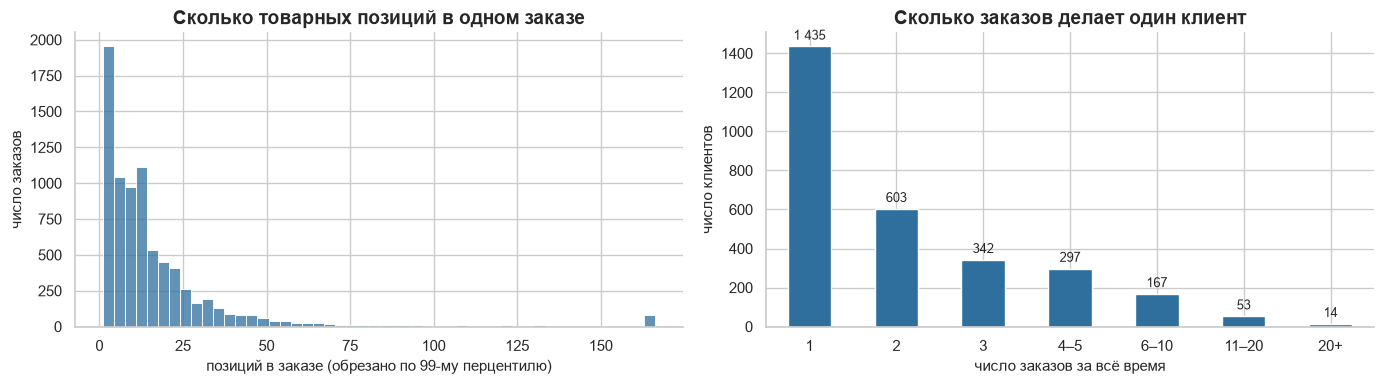

Позиции в заказе:


,count,mean,std,min,25%,50%,75%,max
positions,7 984.00,18.76,35.06,1.00,5.00,11.00,20.00,528.00
revenue,7 984.00,32 164.31,66 902.83,39.00,9 612.00,18 485.00,31 347.25,2 610 834.00


In [20]:
summary_ids = pd.DataFrame({
    'уникальных значений': [df[c].nunique() for c in ['order_id', 'customer_id', 'name_clust', 'entry_id', 'country_id']]
}, index=['order_id (заказы)', 'customer_id (клиенты)', 'name_clust (группы товаров)', 'entry_id (товары)', 'country_id (страны)'])
display(summary_ids.style.format('{:,.0f}'))

order_stats = df.groupby('order_id').agg(positions=('entry_id', 'size'), revenue=('revenue', 'sum')).astype(float)
cust_orders = df.groupby('customer_id')['order_id'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(order_stats['positions'].clip(upper=order_stats['positions'].quantile(.99)), bins=50, ax=axes[0], color=MAIN)
axes[0].set_title('Сколько товарных позиций в одном заказе')
axes[0].set_xlabel('позиций в заказе (обрезано по 99-му перцентилю)')
axes[0].set_ylabel('число заказов')

orders_bins = pd.cut(cust_orders, [0, 1, 2, 3, 5, 10, 20, np.inf], labels=['1', '2', '3', '4–5', '6–10', '11–20', '20+'])
orders_bins.value_counts().sort_index().plot.bar(ax=axes[1], color=MAIN, rot=0)
annotate_bars(axes[1])
axes[1].set_title('Сколько заказов делает один клиент')
axes[1].set_xlabel('число заказов за всё время')
axes[1].set_ylabel('число клиентов')
plt.tight_layout()
plt.show()

print('Позиции в заказе:'); display(order_stats.describe().T)

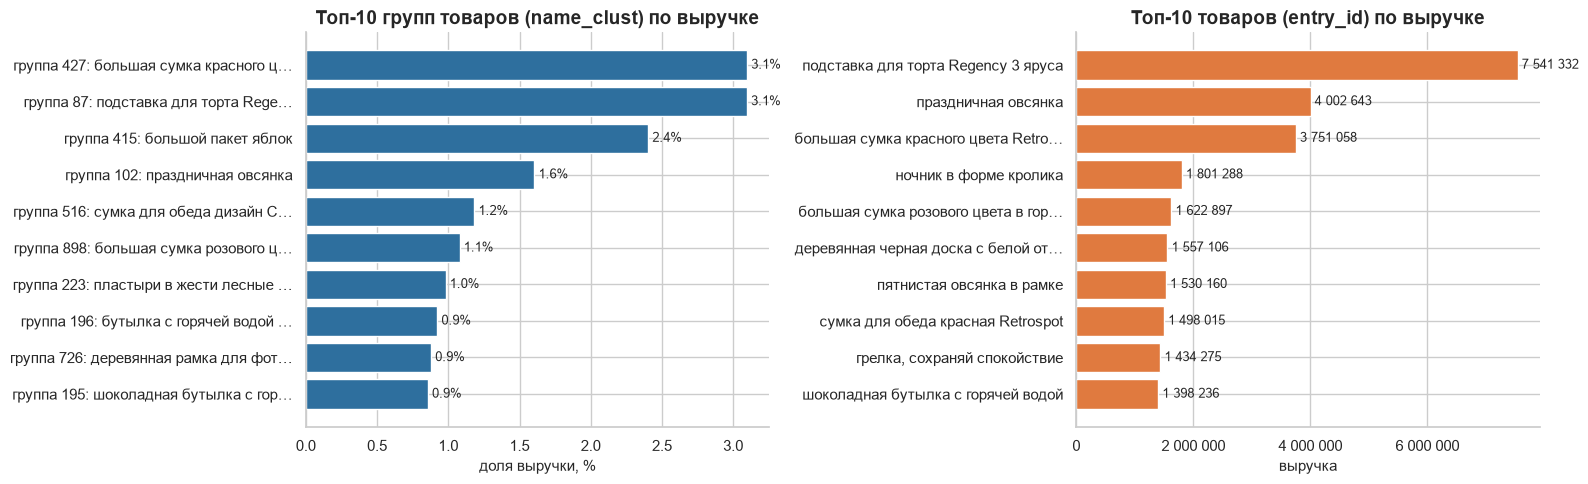

,товаров,заказов,выручка,пример_товара,доля выручки
name_clust,,,,,
427,9,"1,799","7,954,687",большая сумка красного цвета Retrospot,3.1%
87,3,929,"7,952,154",подставка для торта Regency 3 яруса,3.1%
415,7,"1,100","6,171,154",большой пакет яблок,2.4%
102,8,825,"4,120,548",праздничная овсянка,1.6%
516,4,"1,035","3,037,438",сумка для обеда дизайн Суки,1.2%
898,4,977,"2,772,289",большая сумка розового цвета в горошек,1.1%
223,7,770,"2,518,976",пластыри в жести лесные животные,1.0%
196,2,557,"2,369,270",бутылка с горячей водой для собаки Скотти,0.9%
726,4,760,"2,257,077",деревянная рамка для фотографий с белой отделкой,0.9%


In [21]:
names = df.groupby('entry_id')['entry'].first()

clusters = (df.groupby('name_clust')
            .agg(товаров=('entry_id', 'nunique'), заказов=('order_id', 'nunique'), выручка=('revenue', 'sum'),
                 пример_товара=('entry', lambda s: s.value_counts().index[0]))
            .sort_values('выручка', ascending=False))
clusters['доля выручки'] = clusters['выручка'] / clusters['выручка'].sum()

top_products = (df.groupby('entry_id')
                .agg(товар=('entry', 'first'), заказов=('order_id', 'nunique'), штук=('quantity', 'sum'), выручка=('revenue', 'sum'))
                .sort_values('выручка', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_cl = clusters.head(10).iloc[::-1]
axes[0].barh([f'группа {i}: {short(n, 25)}' for i, n in zip(top_cl.index, top_cl['пример_товара'])],
             top_cl['доля выручки'] * 100, color=MAIN)
annotate_bars(axes[0], '{:.1f}%', horizontal=True)
axes[0].set_title('Топ-10 групп товаров (name_clust) по выручке')
axes[0].set_xlabel('доля выручки, %')

top_p = top_products.head(10).iloc[::-1]
axes[1].barh([short(t, 35) for t in top_p['товар']], top_p['выручка'], color=ACCENT)
annotate_bars(axes[1], horizontal=True)
axes[1].set_title('Топ-10 товаров (entry_id) по выручке')
axes[1].set_xlabel('выручка')
thousands(axes[1], 'x')
plt.tight_layout()
plt.show()

display(clusters.head(10).style.format({'товаров': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}', 'доля выручки': '{:.1%}'}))

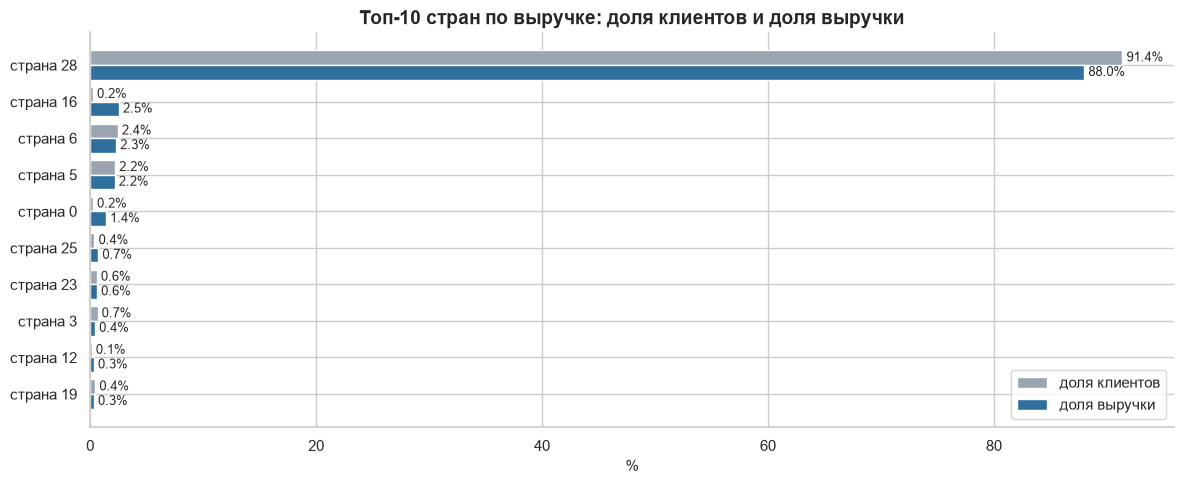

,клиентов,заказов,выручка,доля выручки,доля клиентов
country_id,,,,,
28,"2,660","7,388","225,991,931",88.0%,91.4%
16,7,34,"6,512,960",2.5%,0.2%
6,71,172,"5,878,892",2.3%,2.4%
5,64,164,"5,556,311",2.2%,2.2%
0,7,23,"3,578,018",1.4%,0.2%
25,11,17,"1,827,497",0.7%,0.4%
23,17,34,"1,544,028",0.6%,0.6%
3,19,40,"1,096,528",0.4%,0.7%
12,4,7,"831,110",0.3%,0.1%


In [22]:
countries = (df.groupby('country_id')
             .agg(клиентов=('customer_id', 'nunique'), заказов=('order_id', 'nunique'), выручка=('revenue', 'sum'))
             .sort_values('выручка', ascending=False))
countries['доля выручки'] = countries['выручка'] / countries['выручка'].sum()
countries['доля клиентов'] = countries['клиентов'] / df['customer_id'].nunique()

top_c = countries.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 5))
y = np.arange(len(top_c))
ax.barh(y + 0.2, top_c['доля клиентов'] * 100, height=0.4, color=GREY, label='доля клиентов')
ax.barh(y - 0.2, top_c['доля выручки'] * 100, height=0.4, color=MAIN, label='доля выручки')
ax.set_yticks(y)
ax.set_yticklabels([f'страна {c}' for c in top_c.index])
annotate_bars(ax, '{:.1f}%', horizontal=True)
ax.set_title('Топ-10 стран по выручке: доля клиентов и доля выручки')
ax.set_xlabel('%')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

display(countries.head(10).style.format({'клиентов': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}',
                                         'доля выручки': '{:.1%}', 'доля клиентов': '{:.1%}'}))

In [23]:
main_country = countries.index[0]
S['main_country'], S['main_country_share'] = main_country, countries['доля выручки'].iloc[0]
md(f"""**Вывод по идентификаторам.**
- В очищенных данных **{num(df['order_id'].nunique())}** заказов от **{num(df['customer_id'].nunique())}** клиентов,
  **{num(df['entry_id'].nunique())}** товаров, объединённых в **{num(df['name_clust'].nunique())}** групп по названию, и **{num(df['country_id'].nunique())}** стран.
- В типичном заказе **{num(order_stats['positions'].median())}** товарных позиций, медианная сумма заказа — **{num(order_stats['revenue'].median(), 2)}**.
- **{pct((cust_orders == 1).mean())}** клиентов сделали только один заказ, остальные возвращались.
- Продажи сильно сконцентрированы географически: на страну **{main_country}** приходится **{pct(S['main_country_share'])}** выручки —
  это, по-видимому, домашний рынок магазина. Топ-10 групп товаров дают **{pct(clusters['доля выручки'].head(10).sum())}** выручки.""")

**Вывод по идентификаторам.**
- В очищенных данных **7 984** заказов от **2 911** клиентов,
  **2 697** товаров, объединённых в **902** групп по названию, и **26** стран.
- В типичном заказе **11** товарных позиций, медианная сумма заказа — **18 485.00**.
- **49.3%** клиентов сделали только один заказ, остальные возвращались.
- Продажи сильно сконцентрированы географически: на страну **28** приходится **88.0%** выручки —
  это, по-видимому, домашний рынок магазина. Топ-10 групп товаров дают **16.1%** выручки.

### 2.3. Полнота данных во времени

Посчитаем по каждому месяцу, сколько календарных дней прошло без единой продажи. Дни, не покрытые выгрузкой (в начале первого и в конце последнего месяца), тоже считаются днями без продаж — так сразу видно, какие месяцы выгружены не полностью.

,дней_в_месяце,дней_без_продаж,заказов,дней_с_продажами
дек 2018,31,21,880,10
янв 2019,31,23,362,8
фев 2019,28,18,413,10
мар 2019,31,21,470,10
апр 2019,30,20,507,10
май 2019,31,21,673,10
июн 2019,30,20,581,10
июл 2019,31,21,501,10
авг 2019,31,20,522,11
сен 2019,30,20,613,10


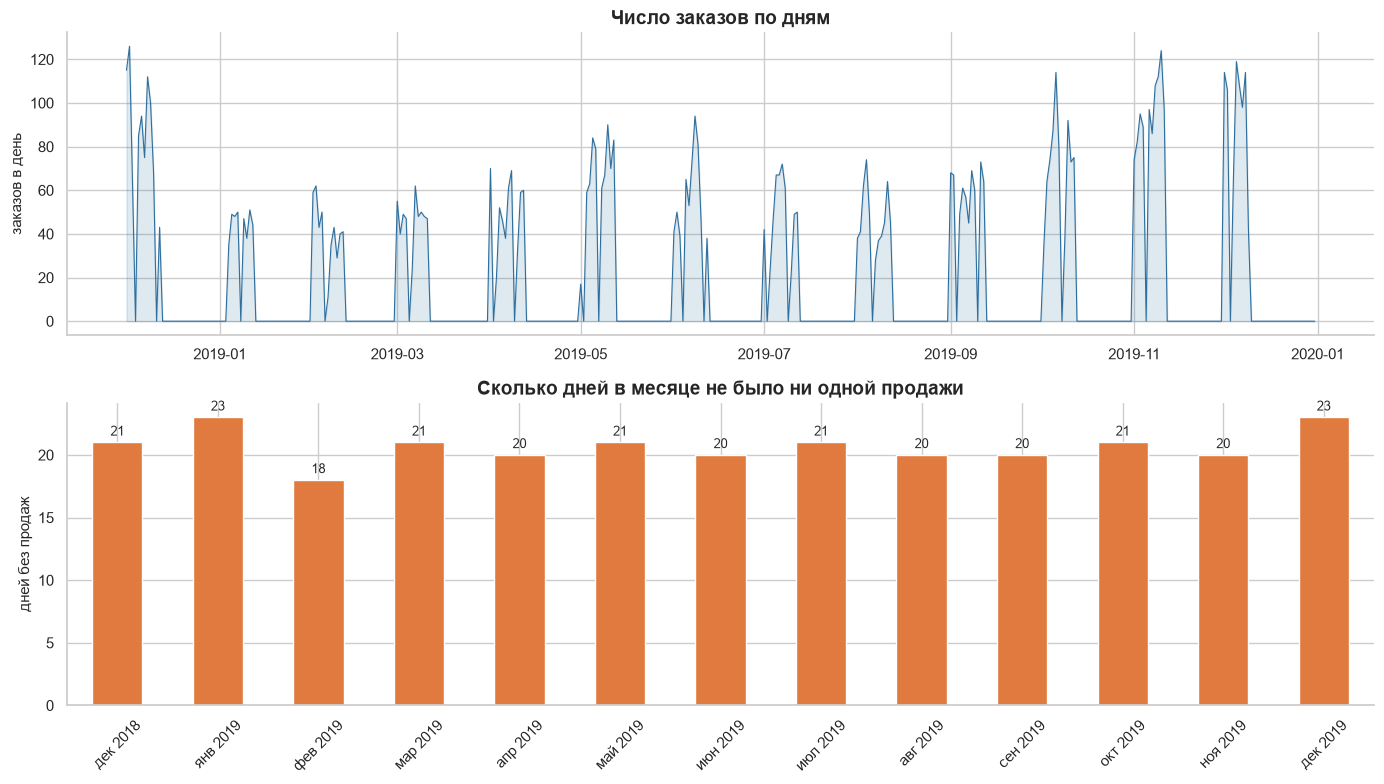

Дни без продаж по дням недели: {'Пн': 34, 'Вт': 57, 'Ср': 36, 'Чт': 38, 'Пт': 34, 'Сб': 35, 'Вс': 35}


In [24]:
day = df['entry_date'].dt.normalize()
daily_orders = df.groupby(day)['order_id'].nunique()
start = daily_orders.index.min().to_period('M').to_timestamp()
end = daily_orders.index.max().to_period('M').to_timestamp(how='end').normalize()
daily_full = daily_orders.reindex(pd.date_range(start, end, freq='D'), fill_value=0)

gaps = pd.DataFrame({'orders': daily_full, 'month': daily_full.index.to_period('M')})
monthly_gaps = gaps.groupby('month').agg(дней_в_месяце=('orders', 'size'),
                                         дней_без_продаж=('orders', lambda s: (s == 0).sum()),
                                         заказов=('orders', 'sum'))
monthly_gaps['дней_с_продажами'] = monthly_gaps['дней_в_месяце'] - monthly_gaps['дней_без_продаж']
monthly_gaps.index = [month_label(p) for p in monthly_gaps.index]
display(monthly_gaps)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(daily_full.index, daily_full.values, color=MAIN, lw=0.8)
axes[0].fill_between(daily_full.index, daily_full.values, color=MAIN, alpha=0.15)
axes[0].set_title('Число заказов по дням')
axes[0].set_ylabel('заказов в день')

monthly_gaps['дней_без_продаж'].plot.bar(ax=axes[1], color=ACCENT, rot=45)
annotate_bars(axes[1])
axes[1].set_title('Сколько дней в месяце не было ни одной продажи')
axes[1].set_ylabel('дней без продаж')
plt.tight_layout()
plt.show()

weekday_share_zero = (daily_full[daily_full == 0].index.weekday.value_counts().reindex(range(7), fill_value=0))
weekday_share_zero.index = WEEKDAYS_RU
print('Дни без продаж по дням недели:', {k: int(v) for k, v in weekday_share_zero.items()})

**Выбор периода.** Месяц считаем полноценным, если в нём продажи были хотя бы в половине от медианного числа «торговых» дней и заказов было не меньше трети от медианного месячного объёма. Берём непрерывный отрезок от первого до последнего полноценного месяца — так исключаются «обрывки» выгрузки по краям, которые занизили бы месячные метрики.

In [25]:
mg = gaps.groupby('month').agg(days_sales=('orders', lambda s: (s > 0).sum()), orders=('orders', 'sum'))
good = mg[(mg['days_sales'] >= 0.5 * mg['days_sales'].median()) & (mg['orders'] >= mg['orders'].median() / 3)].index
PERIOD_START = good.min().to_timestamp()
PERIOD_END = (good.max() + 1).to_timestamp()          # не включительно

rows_before, rev_before = len(df), df['revenue'].sum()
df = df[(df['entry_date'] >= PERIOD_START) & (df['entry_date'] < PERIOD_END)].reset_index(drop=True)
S['period'] = f'{month_label(good.min())} — {month_label(good.max())}'
print(f'Период анализа: {PERIOD_START:%d.%m.%Y} — {(PERIOD_END - pd.Timedelta(days=1)):%d.%m.%Y} ({len(good)} мес.)')
print(f'Сохранено строк: {pct(len(df) / rows_before)}, выручки: {pct(df["revenue"].sum() / rev_before)}')

Период анализа: 01.12.2018 — 31.12.2019 (13 мес.)
Сохранено строк: 100.0%, выручки: 100.0%


In [26]:
md(f"""**Вывод по полноте данных.** Данные охватывают период с **{daily_orders.index.min():%d.%m.%Y}** по **{daily_orders.index.max():%d.%m.%Y}**.
Внутри месяцев регулярно встречаются дни без продаж — в основном это **{weekday_share_zero.idxmax()}**
({weekday_share_zero.max()} таких дней из {weekday_share_zero.sum()}), то есть у магазина есть нерабочий день недели, а также праздничные перерывы.
Крайние месяцы выгрузки неполные, поэтому для анализа оставлен период **{S['period']}** — он содержит основную часть данных
({pct(len(df) / rows_before)} строк). Дальше работаем только с ним.""")

**Вывод по полноте данных.** Данные охватывают период с **01.12.2018** по **09.12.2019**.
Внутри месяцев регулярно встречаются дни без продаж — в основном это **Вт**
(57 таких дней из 269), то есть у магазина есть нерабочий день недели, а также праздничные перерывы.
Крайние месяцы выгрузки неполные, поэтому для анализа оставлен период **дек 2018 — дек 2019** — он содержит основную часть данных
(100.0% строк). Дальше работаем только с ним.

## Шаг 3. Расчёт метрик

### 3.1. Активность покупателей по часам и дням недели

Считаем **число заказов** (уникальные `order_id`) и **число уникальных покупателей** в каждом часе и в каждом дне недели за весь период.

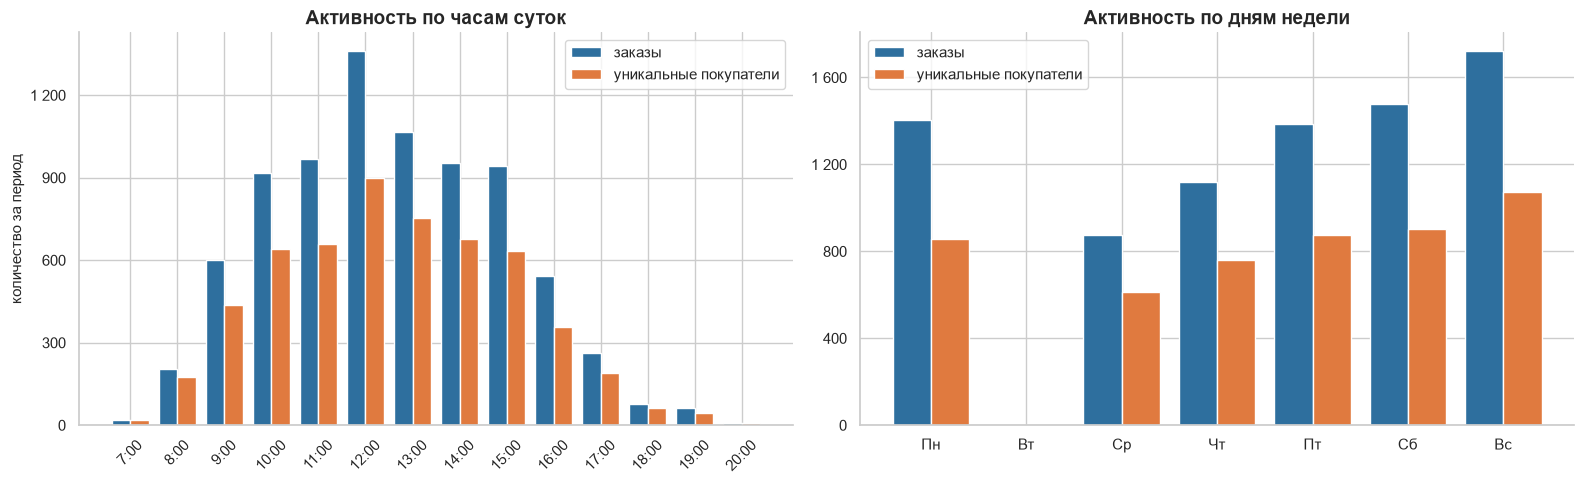

,Пн,Вт,Ср,Чт,Пт,Сб,Вс
заказов,1 406.00,0.00,875.00,1 117.00,1 385.00,1 480.00,1 721.00
покупателей,859.00,0.00,614.00,762.00,876.00,903.00,1 071.00
заказов в среднем за день,24.67,0.00,15.62,19.95,24.73,25.96,30.19


In [27]:
df['hour'] = df['entry_date'].dt.hour
df['weekday'] = df['entry_date'].dt.weekday
df['date'] = df['entry_date'].dt.normalize()
df['month'] = df['entry_date'].dt.to_period('M')

by_hour = df.groupby('hour').agg(заказов=('order_id', 'nunique'), покупателей=('customer_id', 'nunique')).reindex(range(24), fill_value=0)
by_wd = df.groupby('weekday').agg(заказов=('order_id', 'nunique'), покупателей=('customer_id', 'nunique')).reindex(range(7), fill_value=0)
# число календарных дней каждого дня недели в периоде — чтобы посчитать среднее на один такой день
n_wd = pd.Series(pd.date_range(PERIOD_START, PERIOD_END - pd.Timedelta(days=1)).weekday).value_counts().reindex(range(7), fill_value=0)
by_wd['заказов в среднем за день'] = by_wd['заказов'] / n_wd
by_wd.index = WEEKDAYS_RU

hours_active = by_hour[by_hour['заказов'] > 0].index
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(hours_active.min(), hours_active.max() + 1)
axes[0].bar(x - 0.2, by_hour.loc[x, 'заказов'], width=0.4, color=MAIN, label='заказы')
axes[0].bar(x + 0.2, by_hour.loc[x, 'покупателей'], width=0.4, color=ACCENT, label='уникальные покупатели')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{h}:00' for h in x], rotation=45)
axes[0].set_title('Активность по часам суток')
axes[0].set_ylabel('количество за период')
axes[0].legend()
thousands(axes[0])

xw = np.arange(7)
axes[1].bar(xw - 0.2, by_wd['заказов'], width=0.4, color=MAIN, label='заказы')
axes[1].bar(xw + 0.2, by_wd['покупателей'], width=0.4, color=ACCENT, label='уникальные покупатели')
axes[1].set_xticks(xw)
axes[1].set_xticklabels(WEEKDAYS_RU)
axes[1].set_title('Активность по дням недели')
axes[1].legend()
thousands(axes[1])
plt.tight_layout()
plt.show()

display(by_wd.T)

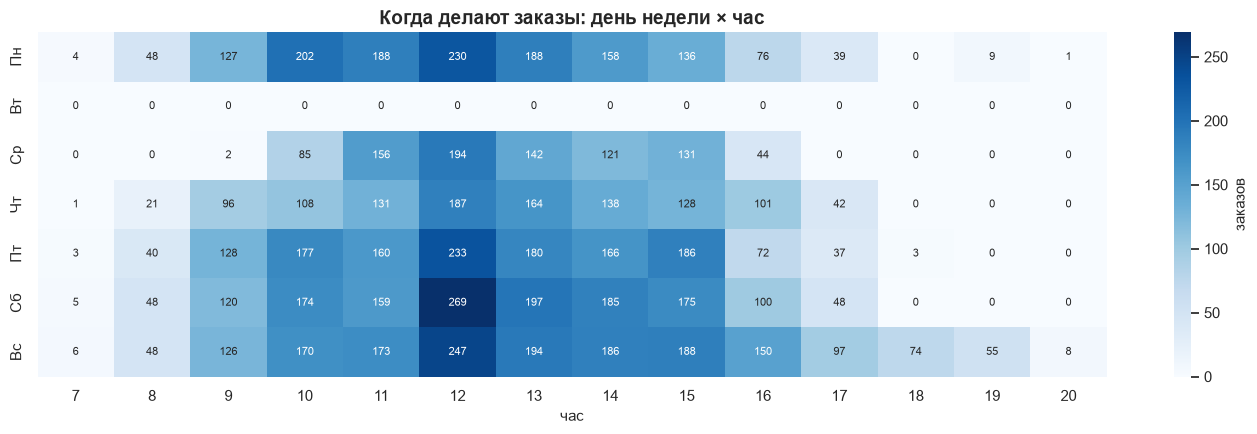

In [28]:
heat = (df.groupby(['weekday', 'hour'])['order_id'].nunique().unstack(fill_value=0)
        .reindex(index=range(7), fill_value=0))
heat = heat.loc[:, heat.sum() > 0]
heat.index = WEEKDAYS_RU
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='Blues', annot=True, fmt='d', annot_kws={'size': 8}, cbar_kws={'label': 'заказов'}, ax=ax)
ax.set_title('Когда делают заказы: день недели × час')
ax.set_xlabel('час')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [29]:
peak_hours = by_hour['заказов'].nlargest(3).index.sort_values()
core = by_hour.loc[10:15, 'заказов'].sum() / by_hour['заказов'].sum()
zero_days = by_wd.index[by_wd['заказов'] == 0].tolist()
S['peak_hours'] = f'{peak_hours.min()}:00–{peak_hours.max() + 1}:00'
S['best_weekday'] = by_wd['заказов в среднем за день'].idxmax()
S['zero_days'] = zero_days
md(f"""**Вывод: цикличность есть, и она выраженная.**
- **Внутри дня.** Заказы идут в «офисное» время: с {hours_active.min()}:00 до {hours_active.max() + 1}:00, пик — **{S['peak_hours']}**.
  На интервал 10:00–16:00 приходится **{pct(core)}** заказов. Это похоже на поведение оптовых и корпоративных клиентов, которые заказывают в рабочее время.
- **Внутри недели.** Больше всего заказов в среднем за день — в **{S['best_weekday']}**, меньше всего — в **{by_wd.loc[by_wd['заказов'] > 0, 'заказов в среднем за день'].idxmin()}**.
  {('В ' + ', '.join(zero_days) + ' заказов нет совсем — магазин в этот день не работает или не принимает заказы.') if zero_days else 'Заказы есть во все дни недели.'}
- Графики заказов и покупателей идут почти параллельно: обычно покупатель делает один заказ за визит, поэтому пик активности — это пик притока клиентов.
- **Для бизнеса:** рассылки и акции лучше запускать утром в будни, чтобы они попадали в пиковые часы; технические работы на сайте — проводить вечером и в нерабочий день.""")

**Вывод: цикличность есть, и она выраженная.**
- **Внутри дня.** Заказы идут в «офисное» время: с 7:00 до 21:00, пик — **11:00–14:00**.
  На интервал 10:00–16:00 приходится **77.7%** заказов. Это похоже на поведение оптовых и корпоративных клиентов, которые заказывают в рабочее время.
- **Внутри недели.** Больше всего заказов в среднем за день — в **Вс**, меньше всего — в **Ср**.
  В Вт заказов нет совсем — магазин в этот день не работает или не принимает заказы.
- Графики заказов и покупателей идут почти параллельно: обычно покупатель делает один заказ за визит, поэтому пик активности — это пик притока клиентов.
- **Для бизнеса:** рассылки и акции лучше запускать утром в будни, чтобы они попадали в пиковые часы; технические работы на сайте — проводить вечером и в нерабочий день.

### 3.2. Средняя выручка с клиента в день и число покупателей по месяцам

**Средняя выручка с клиента в день** = для каждого дня выручка дня ÷ число уникальных покупателей в этот день, затем среднее по дням месяца. Метрика показывает, сколько в среднем приносит один покупатель в день покупки, и не зависит от числа рабочих дней в месяце.

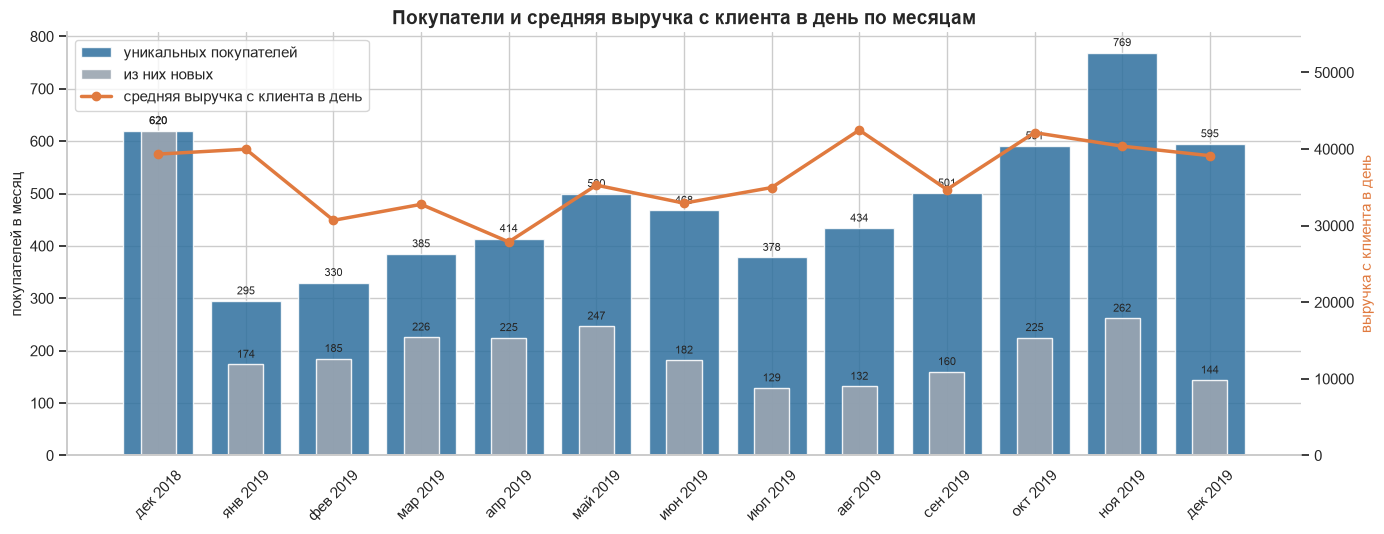

,средняя_выручка_с_клиента_в_день,выручка,уникальных_покупателей,новых_покупателей
дек 2018,"39,345","27,144,921",620,620
янв 2019,"39,985","13,309,575",295,174
фев 2019,"30,698","11,232,233",330,185
мар 2019,"32,782","13,677,958",385,226
апр 2019,"27,880","12,607,599",414,225
май 2019,"35,291","20,062,115",500,247
июн 2019,"32,938","16,088,440",468,182
июл 2019,"34,977","14,641,887",378,129
авг 2019,"42,479","21,146,006",434,132
сен 2019,"34,721","18,792,604",501,160


In [30]:
daily = df.groupby('date').agg(выручка=('revenue', 'sum'), покупателей=('customer_id', 'nunique'))
daily['выручка_на_клиента'] = daily['выручка'] / daily['покупателей']
daily['month'] = daily.index.to_period('M')

monthly = daily.groupby('month').agg(средняя_выручка_с_клиента_в_день=('выручка_на_клиента', 'mean'),
                                     выручка=('выручка', 'sum'))
monthly['уникальных_покупателей'] = df.groupby('month')['customer_id'].nunique()
monthly['новых_покупателей'] = df.groupby('customer_id')['month'].min().value_counts().reindex(monthly.index, fill_value=0)
labels = [month_label(p) for p in monthly.index]

fig, ax1 = plt.subplots(figsize=(14, 5.5))
bars = ax1.bar(labels, monthly['уникальных_покупателей'], color=MAIN, alpha=0.85, label='уникальных покупателей')
ax1.bar(labels, monthly['новых_покупателей'], color=GREY, alpha=0.9, width=0.4, label='из них новых')
ax1.set_ylabel('покупателей в месяц')
annotate_bars(ax1, fontsize=8)
ax2 = ax1.twinx()
ax2.plot(labels, monthly['средняя_выручка_с_клиента_в_день'], color=ACCENT, marker='o', lw=2.5,
         label='средняя выручка с клиента в день')
ax2.set_ylabel('выручка с клиента в день', color=ACCENT)
ax2.set_ylim(0, monthly['средняя_выручка_с_клиента_в_день'].max() * 1.3)
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
ax1.set_title('Покупатели и средняя выручка с клиента в день по месяцам')
plt.setp(ax1.get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

monthly_show = monthly.copy()
monthly_show.index = labels
display(monthly_show.style.format('{:,.0f}'))

In [31]:
mc = monthly['уникальных_покупателей']
arpu_d = monthly['средняя_выручка_с_клиента_в_день']
first_half = mc.iloc[:len(mc) // 2].mean()
second_half = mc.iloc[len(mc) // 2:].mean()
S['best_month'] = month_label(mc.idxmax())
S['cust_growth'] = mc.max() / mc.min() - 1
md(f"""**Вывод о сезонности.**
- Число покупателей в месяц меняется от **{num(mc.min())}** ({month_label(mc.idxmin())}) до **{num(mc.max())}** ({S['best_month']}),
  то есть в лучший месяц покупателей на **{pct(S['cust_growth'], 0)}** больше, чем в худший.
  Во второй половине периода покупателей в среднем **{'больше' if second_half > first_half else 'меньше'}**, чем в первой ({num(second_half)} против {num(first_half)}).
- Средняя выручка с клиента в день колеблется в диапазоне **{num(arpu_d.min())}–{num(arpu_d.max())}** и меняется заметно слабее, чем число покупателей:
  рост выручки в сильные месяцы обеспечивается прежде всего **притоком покупателей**, а не ростом чека.
- {'Пик приходится на предпраздничный период (осень — начало зимы) — это ожидаемо для магазина подарков: клиенты, включая оптовиков, закупаются к Рождеству и Новому году.' if mc.idxmax().month in (9, 10, 11, 12) else 'Пик приходится не на предпраздничный период, что для магазина подарков неожиданно — стоит уточнить у бизнеса, не было ли в этот месяц акций или крупных клиентов.'}
  Но данных всего за один год: отличить устойчивую сезонность от разового роста бизнеса нельзя — для уверенного вывода нужна история минимум за 2–3 года.""")

**Вывод о сезонности.**
- Число покупателей в месяц меняется от **295** (янв 2019) до **769** (ноя 2019),
  то есть в лучший месяц покупателей на **161%** больше, чем в худший.
  Во второй половине периода покупателей в среднем **больше**, чем в первой (534 против 424).
- Средняя выручка с клиента в день колеблется в диапазоне **27 880–42 479** и меняется заметно слабее, чем число покупателей:
  рост выручки в сильные месяцы обеспечивается прежде всего **притоком покупателей**, а не ростом чека.
- Пик приходится на предпраздничный период (осень — начало зимы) — это ожидаемо для магазина подарков: клиенты, включая оптовиков, закупаются к Рождеству и Новому году.
  Но данных всего за один год: отличить устойчивую сезонность от разового роста бизнеса нельзя — для уверенного вывода нужна история минимум за 2–3 года.

### 3.3. Sticky factor за II и III кварталы 2019 года

**Sticky factor** («липкость») = DAU / MAU — какая доля месячной аудитории приходит в магазин в среднестатистический день.
- DAU — среднее число уникальных покупателей за день (по дням с продажами — в нерабочие дни магазин не торгует, и они искусственно занизили бы метрику);
- MAU — среднее число уникальных покупателей за месяц квартала.

Для полноты добавим DAU / WAU (WAU — уникальные покупатели за неделю).

,DAU,WAU,MAU,sticky DAU/MAU,sticky DAU/WAU,покупателей за квартал
2019Q2,50.3,206.0,460.7,10.93%,24.43%,"1,103"
2019Q3,46.3,172.1,437.7,10.58%,26.91%,"1,022"


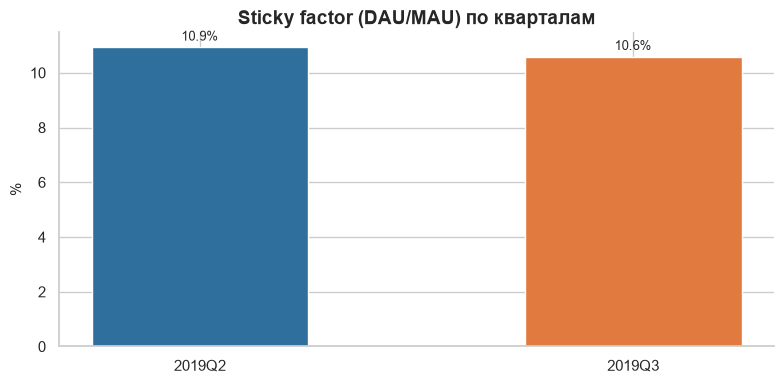

In [32]:
def sticky(q):
    sub = df[df['entry_date'].dt.to_period('Q') == pd.Period(q, freq='Q')]
    if sub.empty:
        return None
    dau = sub.groupby('date')['customer_id'].nunique().mean()
    wau = sub.groupby(sub['entry_date'].dt.to_period('W'))['customer_id'].nunique().mean()
    mau = sub.groupby('month')['customer_id'].nunique().mean()
    return {'DAU': dau, 'WAU': wau, 'MAU': mau, 'sticky DAU/MAU': dau / mau, 'sticky DAU/WAU': dau / wau,
            'покупателей за квартал': sub['customer_id'].nunique()}


quarters = ['2019Q2', '2019Q3']
sticky_tbl = pd.DataFrame({q: sticky(q) for q in quarters if sticky(q) is not None}).T
if len(sticky_tbl) < 2:
    print('Внимание: в периоде анализа нет одного из кварталов 2019 года')
display(sticky_tbl.style.format({'DAU': '{:.1f}', 'WAU': '{:.1f}', 'MAU': '{:.1f}', 'sticky DAU/MAU': '{:.2%}',
                                 'sticky DAU/WAU': '{:.2%}', 'покупателей за квартал': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sticky_tbl.index, sticky_tbl['sticky DAU/MAU'] * 100, color=[MAIN, ACCENT][:len(sticky_tbl)], width=0.5)
annotate_bars(ax, '{:.1f}%')
ax.set_title('Sticky factor (DAU/MAU) по кварталам')
ax.set_ylabel('%')
plt.tight_layout()
plt.show()

In [33]:
S['sticky'] = sticky_tbl['sticky DAU/MAU'].to_dict()
q2, q3 = (sticky_tbl['sticky DAU/MAU'].get(q, np.nan) for q in quarters)
md(f"""**Вывод.** Sticky factor во II квартале — **{pct(q2)}**, в III квартале — **{pct(q3)}**
({'вырос' if q3 > q2 else 'снизился'} на {abs(q3 - q2) * 100:.1f} п.п.). Это значит, что в обычный рабочий день в магазин заходит лишь
около {pct((q2 + q3) / 2, 0)} покупателей, которые купят что-то в течение месяца.
Для магазина подарков это нормально: покупки делаются по поводу (праздник, пополнение склада у оптовика), а не каждый день.
Метрику полезнее отслеживать в динамике: её рост означает, что клиенты стали возвращаться чаще.""")

**Вывод.** Sticky factor во II квартале — **10.9%**, в III квартале — **10.6%**
(снизился на 0.3 п.п.). Это значит, что в обычный рабочий день в магазин заходит лишь
около 11% покупателей, которые купят что-то в течение месяца.
Для магазина подарков это нормально: покупки делаются по поводу (праздник, пополнение склада у оптовика), а не каждый день.
Метрику полезнее отслеживать в динамике: её рост означает, что клиенты стали возвращаться чаще.

### 3.4. Профиль клиента

Сначала соберём таблицу заказов (одна строка — один заказ), затем по ней — профиль каждого клиента:

| Показатель | Что значит |
|---|---|
| `orders` | число заказов |
| `first_order`, `last_order` | дата первого и последнего заказа |
| `revenue` | общая сумма всех заказов |
| `aov` | средняя стоимость заказа (средний чек) |
| `avg_items`, `avg_positions` | среднее число штук и товарных позиций в заказе |
| `unique_products` | сколько разных товаров купил клиент |
| `lifetime_days` | дней между первым и последним заказом |
| `avg_days_between` | средний интервал между заказами (для возвратных) |
| `recency` | дней с последнего заказа до конца периода |
| `country_id` | страна, в которую клиент заказывал чаще всего |

In [34]:
orders = (df.groupby('order_id')
          .agg(customer_id=('customer_id', 'first'), order_date=('entry_date', 'min'), revenue=('revenue', 'sum'),
               items=('quantity', 'sum'), positions=('entry_id', 'nunique'), country_id=('country_id', 'first'))
          .reset_index())
orders['quarter'] = orders['order_date'].dt.to_period('Q')

SNAPSHOT = PERIOD_END   # день после окончания периода анализа

profile = orders.groupby('customer_id').agg(
    orders=('order_id', 'nunique'),
    first_order=('order_date', 'min'),
    last_order=('order_date', 'max'),
    revenue=('revenue', 'sum'),
    aov=('revenue', 'mean'),
    avg_items=('items', 'mean'),
    avg_positions=('positions', 'mean'),
)
profile['unique_products'] = df.groupby('customer_id')['entry_id'].nunique()
profile['country_id'] = df.groupby('customer_id')['country_id'].agg(lambda s: s.mode().iat[0])
profile['lifetime_days'] = (profile['last_order'] - profile['first_order']).dt.days
profile['avg_days_between'] = np.where(profile['orders'] > 1, profile['lifetime_days'] / (profile['orders'] - 1), np.nan)
profile['recency'] = (SNAPSHOT - profile['last_order']).dt.days
profile['is_returning'] = profile['orders'] > 1
profile['тип клиента'] = np.where(profile['is_returning'], 'возвратный', 'разовый')

print(f'Профилей клиентов: {num(len(profile))}')
display(profile.head(10))
display(profile.describe().T)

Профилей клиентов: 2 911


,orders,first_order,last_order,revenue,aov,avg_items,avg_positions,unique_products,country_id,lifetime_days,avg_days_between,recency,is_returning,тип клиента
customer_id,,,,,,,,,,,,,,
-1,540,2018-12-01 14:32:00,2019-12-09 10:26:00,44 012 409.00,81 504.46,233.74,73.80,2221,28,372,0.69,22,True,возвратный
1713,1,2019-10-12 10:23:00,2019-10-12 10:23:00,67 156.00,67 156.00,576.00,21.00,21,28,0,NaN,80,False,разовый
1717,4,2019-01-06 14:14:00,2019-12-06 12:02:00,38 915.00,9 728.75,66.00,39.00,97,28,333,111.00,25,True,возвратный
1718,2,2019-08-05 13:35:00,2019-12-02 11:43:00,11 886.00,5 943.00,39.00,4.00,8,28,118,118.00,29,True,возвратный
1719,1,2019-06-12 10:53:00,2019-06-12 10:53:00,8 082.00,8 082.00,54.00,7.00,7,28,0,NaN,202,False,разовый
1720,1,2019-03-07 09:52:00,2019-03-07 09:52:00,13 290.00,13 290.00,35.00,7.00,7,28,0,NaN,299,False,разовый
1723,1,2019-10-12 15:22:00,2019-10-12 15:22:00,2 806.00,2 806.00,40.00,3.00,3,28,0,NaN,80,False,разовый
1726,1,2019-11-09 17:03:00,2019-11-09 17:03:00,10 710.00,10 710.00,42.00,7.00,7,28,0,NaN,52,False,разовый
1727,2,2019-09-05 11:27:00,2019-12-07 13:16:00,15 300.00,7 650.00,30.00,1.00,1,28,93,93.00,24,True,возвратный


,count,mean,min,25%,50%,75%,max,std
orders,2 911.00,2.74,1.00,1.00,2.00,3.00,540.00,10.57
first_order,2911,2019-05-09 10:41:28.381999,2018-12-01 08:26:00,2019-01-10 10:33:30,2019-05-04 08:40:00,2019-09-05 16:59:00,2019-12-09 12:16:00,NaN
last_order,2911,2019-08-13 00:13:14.737203,2018-12-01 09:53:00,2019-05-12 13:26:30,2019-10-04 09:09:00,2019-11-10 09:09:00,2019-12-09 12:50:00,NaN
revenue,2 911.00,88 217.06,590.00,14 647.50,30 060.00,68 939.00,44 012 409.00,846 338.55
aov,2 911.00,24 785.66,590.00,10 783.33,18 180.00,28 396.00,527 916.00,29 767.24
avg_items,2 911.00,152.53,1.00,57.10,105.50,186.00,2 468.00,183.92
avg_positions,2 911.00,14.91,1.00,6.00,11.00,19.00,182.67,14.51
unique_products,2 911.00,31.08,1.00,8.00,18.00,38.00,2 221.00,57.79
country_id,2 911.00,26.44,0.00,28.00,28.00,28.00,29.00,5.57
lifetime_days,2 911.00,95.32,0.00,0.00,0.00,184.00,373.00,126.10


### 3.5. Возвратные и разовые клиенты

**Возвратный клиент** — сделал больше одного заказа за период; **разовый** — ровно один. Для разовых не определены интервал между заказами и «срок жизни» — их сравниваем только по сопоставимым показателям.

In [35]:
metrics = ['orders', 'revenue', 'aov', 'avg_items', 'avg_positions', 'unique_products', 'recency', 'lifetime_days', 'avg_days_between']
grp = profile.groupby('тип клиента')
comp = pd.concat({'среднее': grp[metrics].mean().T, 'медиана': grp[metrics].median().T}, axis=1)
comp.index = ['заказов', 'сумма всех заказов', 'средний чек', 'штук в заказе', 'позиций в заказе',
              'разных товаров', 'дней с последнего заказа', 'дней между 1-м и последним заказом', 'дней между заказами']
display(comp.style.format('{:,.1f}', na_rep='—'))

shares = pd.DataFrame({
    'клиентов': grp.size(),
    'доля клиентов': grp.size() / len(profile),
    'доля выручки': grp['revenue'].sum() / profile['revenue'].sum(),
})
display(shares.style.format({'клиентов': '{:,.0f}', 'доля клиентов': '{:.1%}', 'доля выручки': '{:.1%}'}))

,клиентов,доля клиентов,доля выручки
тип клиента,,,
возвратный,"1,476",50.7%,87.0%
разовый,"1,435",49.3%,13.0%


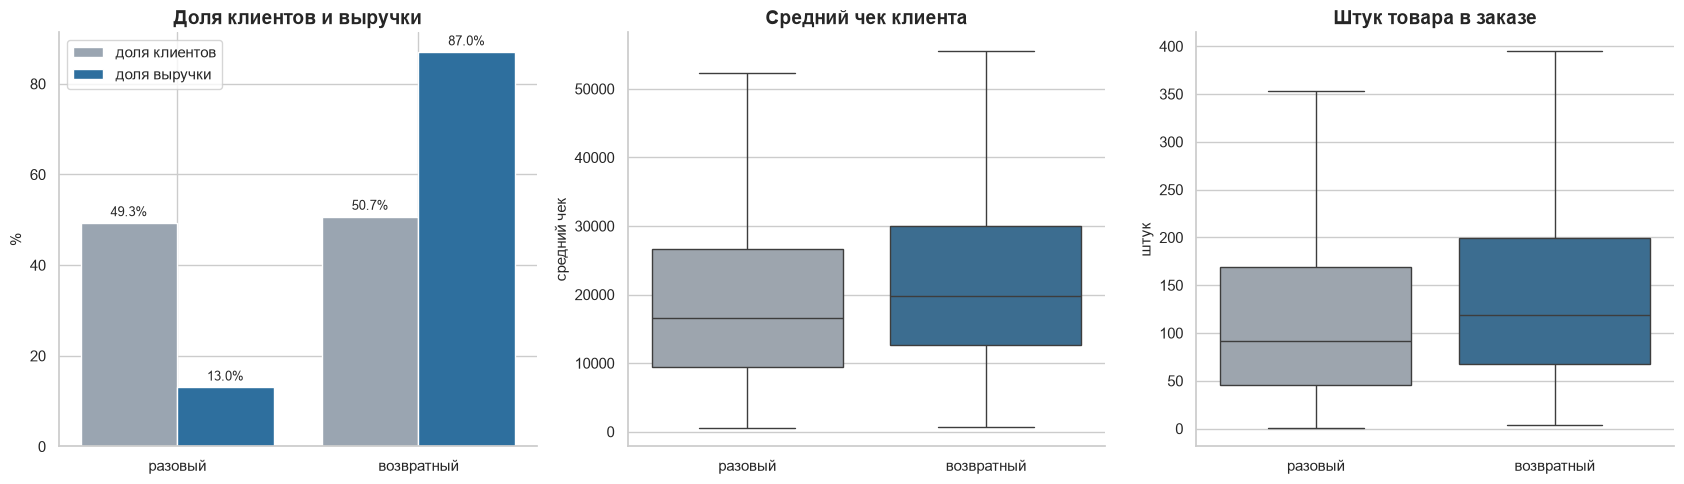

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
order_types = ['разовый', 'возвратный']
palette = {'разовый': GREY, 'возвратный': MAIN}

sh = shares.reindex(order_types)
x = np.arange(2)
axes[0].bar(x - 0.2, sh['доля клиентов'] * 100, width=0.4, color=GREY, label='доля клиентов')
axes[0].bar(x + 0.2, sh['доля выручки'] * 100, width=0.4, color=MAIN, label='доля выручки')
axes[0].set_xticks(x); axes[0].set_xticklabels(order_types)
annotate_bars(axes[0], '{:.1f}%')
axes[0].set_title('Доля клиентов и выручки')
axes[0].set_ylabel('%'); axes[0].legend()

sns.boxplot(data=profile, x='тип клиента', y='aov', order=order_types, palette=palette, ax=axes[1], showfliers=False)
axes[1].set_title('Средний чек клиента')
axes[1].set_ylabel('средний чек'); axes[1].set_xlabel('')

sns.boxplot(data=profile, x='тип клиента', y='avg_items', order=order_types, palette=palette, ax=axes[2], showfliers=False)
axes[2].set_title('Штук товара в заказе')
axes[2].set_ylabel('штук'); axes[2].set_xlabel('')
plt.tight_layout()
plt.show()

In [37]:
ret, one = profile[profile['is_returning']], profile[~profile['is_returning']]
S['returning_share'] = len(ret) / len(profile)
S['returning_rev_share'] = ret['revenue'].sum() / profile['revenue'].sum()
md(f"""**Вывод.**
- Возвратных клиентов **{pct(S['returning_share'])}**, и они приносят **{pct(S['returning_rev_share'])}** выручки:
  в среднем возвратный клиент сделал **{ret['orders'].mean():.1f}** заказа и потратил **{num(ret['revenue'].mean())}** против **{num(one['revenue'].mean())}** у разового
  (в **{ret['revenue'].mean() / one['revenue'].mean():.1f}** раза больше).
- Средний чек: у возвратных — **{num(ret['aov'].median())}**, у разовых — **{num(one['aov'].median())}** (медианы).
  {'Возвратные клиенты тратят за заказ больше: среди них больше оптовиков.' if ret['aov'].median() > one['aov'].median() else 'Чек разовых клиентов не ниже, чем у возвратных: основная разница в выручке — за счёт числа заказов, а не размера заказа.'}
- Возвратные клиенты покупают в среднем **{ret['unique_products'].mean():.0f}** разных товаров против **{one['unique_products'].mean():.0f}** у разовых — они знакомы с ассортиментом шире.
- Типичный интервал между заказами у возвратных — **{ret['avg_days_between'].median():.0f}** дней (медиана): это ориентир, когда напоминать клиенту о себе.
- **Главное для бизнеса:** удержание клиента после первой покупки — ключевой рычаг роста: каждый вернувшийся клиент кратно ценнее разового.""")

**Вывод.**
- Возвратных клиентов **50.7%**, и они приносят **87.0%** выручки:
  в среднем возвратный клиент сделал **4.4** заказа и потратил **151 314** против **23 318** у разового
  (в **6.5** раза больше).
- Средний чек: у возвратных — **19 810**, у разовых — **16 517** (медианы).
  Возвратные клиенты тратят за заказ больше: среди них больше оптовиков.
- Возвратные клиенты покупают в среднем **47** разных товаров против **15** у разовых — они знакомы с ассортиментом шире.
- Типичный интервал между заказами у возвратных — **69** дней (медиана): это ориентир, когда напоминать клиенту о себе.
- **Главное для бизнеса:** удержание клиента после первой покупки — ключевой рычаг роста: каждый вернувшийся клиент кратно ценнее разового.

## Шаг 4. RFM-сегментация клиентов

RFM делит клиентов по трём вопросам:
- **R (Recency)** — как давно клиент покупал последний раз (дней до конца периода; меньше — лучше);
- **F (Frequency)** — сколько заказов он сделал;
- **M (Monetary)** — сколько денег принёс.

Каждый показатель оцениваем по шкале от 1 до 3 (3 — лучшее значение):
- **R и M** — по терцилям: треть клиентов с лучшими значениями получает 3, следующая треть — 2, остальные — 1;
- **F** — терцили не подходят, потому что большинство клиентов сделали ровно один заказ. Поэтому: 1 заказ → F=1; возвратные клиенты делятся по медиане числа заказов среди возвратных на F=2 и F=3.

Затем по сочетанию R и F присваиваем понятный бизнесу сегмент, а M показывает его денежную ценность.

In [38]:
rfm = profile[['recency', 'orders', 'revenue', 'aov']].copy()

r1, r2 = rfm['recency'].quantile([1 / 3, 2 / 3])
m1, m2 = rfm['revenue'].quantile([1 / 3, 2 / 3])
f_med = rfm.loc[rfm['orders'] > 1, 'orders'].median()

rfm['R'] = np.select([rfm['recency'] <= r1, rfm['recency'] <= r2], [3, 2], default=1)
rfm['F'] = np.select([rfm['orders'] == 1, rfm['orders'] <= f_med], [1, 2], default=3)
rfm['M'] = np.select([rfm['revenue'] > m2, rfm['revenue'] > m1], [3, 2], default=1)
rfm['RFM'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

thresholds = pd.DataFrame({
    '3 балла': [f'≤ {r1:.0f} дн.', f'> {f_med:.0f} заказов', f'> {num(m2)}'],
    '2 балла': [f'{r1:.0f}–{r2:.0f} дн.', f'2–{f_med:.0f} заказа', f'{num(m1)}–{num(m2)}'],
    '1 балл': [f'> {r2:.0f} дн.', '1 заказ', f'≤ {num(m1)}'],
}, index=['R — дней с последнего заказа', 'F — число заказов', 'M — сумма всех заказов'])
display(thresholds)

,3 балла,2 балла,1 балл
R — дней с последнего заказа,≤ 57 дн.,57–177 дн.,> 177 дн.
F — число заказов,> 3 заказов,2–3 заказа,1 заказ
M — сумма всех заказов,> 50 717,19 103–50 717,≤ 19 103


In [39]:
def segment(row):
    r, f = row['R'], row['F']
    if r == 3 and f == 3:
        return 'Чемпионы'
    if r >= 2 and f >= 2:
        return 'Лояльные'
    if r == 3 and f == 1:
        return 'Новички'
    if r == 2 and f == 1:
        return 'Требуют внимания'
    if r == 1 and f >= 2:
        return 'Под угрозой ухода'
    return 'Потерянные'


SEG_ORDER = ['Чемпионы', 'Лояльные', 'Новички', 'Требуют внимания', 'Под угрозой ухода', 'Потерянные']
SEG_COLORS = dict(zip(SEG_ORDER, ['#1B5E8C', '#4A90C2', '#3A9D5D', '#E0B13F', '#E07A3F', '#9AA5B1']))
rfm['сегмент'] = rfm.apply(segment, axis=1)

seg = (rfm.groupby('сегмент')
       .agg(клиентов=('R', 'size'), R_дней=('recency', 'mean'), F_заказов=('orders', 'mean'),
            M_выручка=('revenue', 'mean'), медиана_M=('revenue', 'median'), средний_чек=('aov', 'median'),
            выручка=('revenue', 'sum'))
       .reindex(SEG_ORDER).dropna(subset=['клиентов']))
seg['доля клиентов'] = seg['клиентов'] / seg['клиентов'].sum()
seg['доля выручки'] = seg['выручка'] / seg['выручка'].sum()
seg['доля с M=3'] = rfm.groupby('сегмент')['M'].apply(lambda s: (s == 3).mean()).reindex(seg.index)
display(seg.style.format({'клиентов': '{:,.0f}', 'R_дней': '{:.0f}', 'F_заказов': '{:.1f}', 'M_выручка': '{:,.0f}',
                          'медиана_M': '{:,.0f}', 'средний_чек': '{:,.0f}', 'выручка': '{:,.0f}',
                          'доля клиентов': '{:.1%}', 'доля выручки': '{:.1%}', 'доля с M=3': '{:.0%}'})
        .background_gradient(subset=['доля выручки'], cmap='Blues'))

,клиентов,R_дней,F_заказов,M_выручка,медиана_M,средний_чек,выручка,доля клиентов,доля выручки,доля с M=3
сегмент,,,,,,,,,,
Чемпионы,364,34,9.4,"389,380","134,194","22,133","141,734,461",12.5%,55.2%,93%
Лояльные,880,76,2.9,"77,043","51,156","19,740","67,798,139",30.2%,26.4%,50%
Новички,281,40,1.0,"23,504","17,116","17,116","6,604,744",9.7%,2.6%,8%
Требуют внимания,418,106,1.0,"26,320","18,410","18,410","11,001,649",14.4%,4.3%,10%
Под угрозой ухода,232,253,2.6,"59,511","39,669","16,946","13,806,489",8.0%,5.4%,36%
Потерянные,736,293,1.0,"21,541","15,000","15,000","15,854,372",25.3%,6.2%,5%


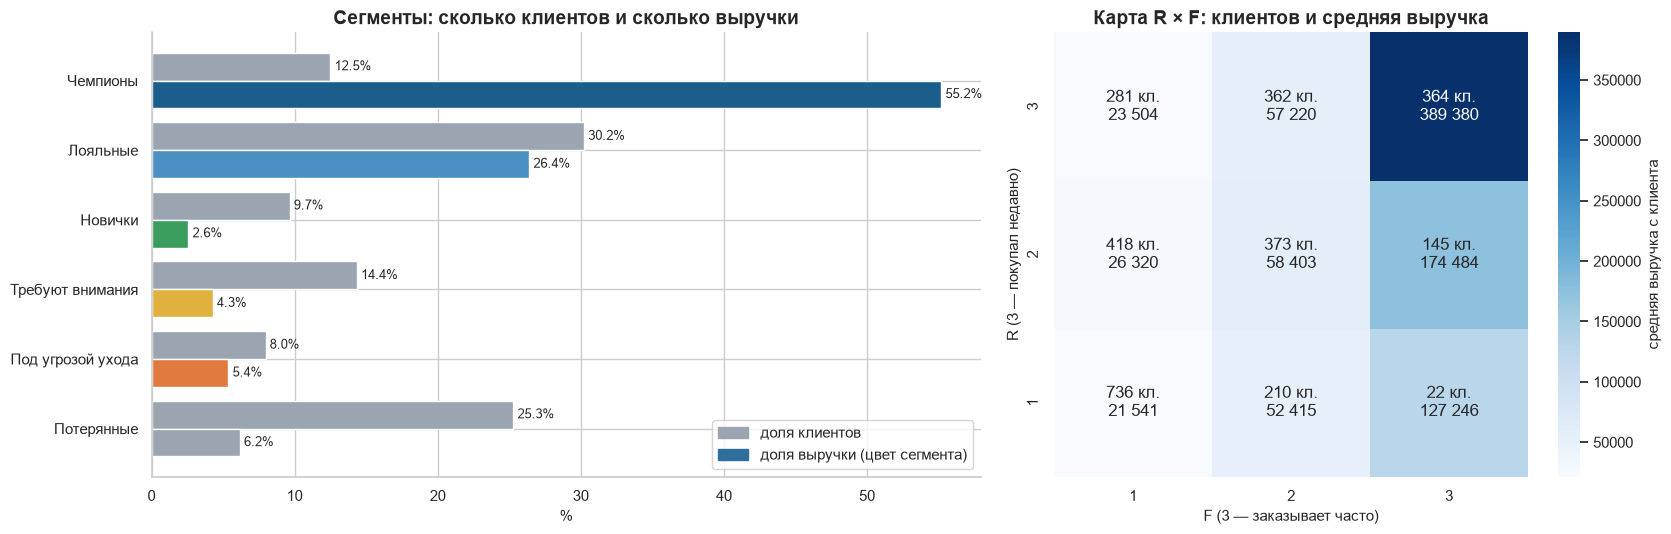

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.4, 1]})

s = seg.iloc[::-1]
y = np.arange(len(s))
axes[0].barh(y + 0.2, s['доля клиентов'] * 100, height=0.4, color=GREY, label='доля клиентов')
axes[0].barh(y - 0.2, s['доля выручки'] * 100, height=0.4, color=[SEG_COLORS[i] for i in s.index], label='доля выручки')
axes[0].set_yticks(y); axes[0].set_yticklabels(s.index)
annotate_bars(axes[0], '{:.1f}%', horizontal=True)
axes[0].set_title('Сегменты: сколько клиентов и сколько выручки')
from matplotlib.patches import Patch
axes[0].set_xlabel('%')
axes[0].legend(handles=[Patch(color=GREY, label='доля клиентов'), Patch(color=MAIN, label='доля выручки (цвет сегмента)')], loc='lower right')

cnt = rfm.pivot_table(index='R', columns='F', values='revenue', aggfunc='size', fill_value=0).sort_index(ascending=False)
mean_m = rfm.pivot_table(index='R', columns='F', values='revenue', aggfunc='mean').sort_index(ascending=False)
m_int = mean_m.round(0).fillna(0).astype(int)
elementwise = getattr(m_int, 'map', None) or m_int.applymap      # DataFrame.map есть только в pandas ≥ 2.1
annot = cnt.astype(str) + ' кл.\n' + elementwise(lambda v: f'{v:,}'.replace(',', ' '))
sns.heatmap(mean_m, annot=annot, fmt='', cmap='Blues', ax=axes[1], cbar_kws={'label': 'средняя выручка с клиента'})
axes[1].set_title('Карта R × F: клиентов и средняя выручка')
axes[1].set_ylabel('R (3 — покупал недавно)')
axes[1].set_xlabel('F (3 — заказывает часто)')
plt.tight_layout()
plt.show()

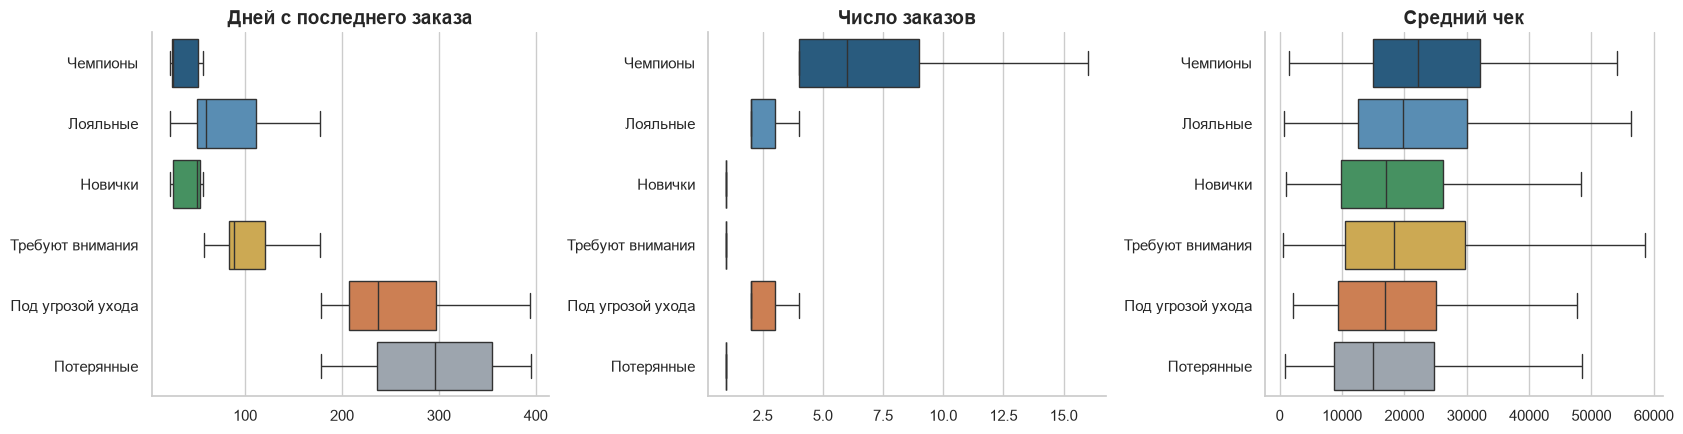

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ['recency', 'orders', 'aov'], ['Дней с последнего заказа', 'Число заказов', 'Средний чек']):
    sns.boxplot(data=rfm, y='сегмент', x=col, order=[s for s in SEG_ORDER if s in seg.index],
                palette=SEG_COLORS, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [42]:
top2 = seg.loc[[s for s in ['Чемпионы', 'Лояльные'] if s in seg.index]]
risk = seg.loc[[s for s in ['Под угрозой ухода'] if s in seg.index]]
newb = seg.loc[[s for s in ['Новички', 'Требуют внимания', 'Потерянные'] if s in seg.index]]
S['seg_top_cust'], S['seg_top_rev'] = top2['доля клиентов'].sum(), top2['доля выручки'].sum()
S['seg_risk_rev'] = risk['доля выручки'].sum()
S['seg_one_cust'], S['seg_one_rev'] = newb['доля клиентов'].sum(), newb['доля выручки'].sum()
aov_med = seg['средний_чек']
md(f"""**Оценка сегментов.**
- **Чемпионы и Лояльные** — {pct(S['seg_top_cust'])} клиентов и **{pct(S['seg_top_rev'])}** выручки. Это ядро бизнеса: покупают недавно и часто.
  Оба сегмента — недавние возвратные покупатели; «Чемпионы» отличаются от «Лояльных» более высокой частотой и, как следствие, суммой покупок.
- **Под угрозой ухода** — в среднем {seg.loc['Под угрозой ухода', 'F_заказов'] if 'Под угрозой ухода' in seg.index else float('nan'):.1f} заказа и выручка {num(seg['M_выручка'].get('Под угрозой ухода', np.nan))} на клиента
  (у «Лояльных» — {seg['F_заказов'].get('Лояльные', np.nan):.1f} заказа и {num(seg['M_выручка'].get('Лояльные', np.nan))}): по истории покупок они ближе к лояльным, но давно не возвращались ({seg['R_дней'].get('Под угрозой ухода', np.nan):.0f} дней в среднем).
  На них приходится **{pct(S['seg_risk_rev'])}** выручки — это деньги, которые можно потерять.
- **Новички, Требуют внимания, Потерянные** — клиенты с одним заказом ({pct(S['seg_one_cust'])} клиентов, но лишь {pct(S['seg_one_rev'])} выручки).
  Между собой они похожи по частоте и чеку, а различаются только давностью покупки — то есть шансом ещё вернуть клиента.
- Средний чек (медиана) по сегментам: {', '.join(f'{k} — {num(v)}' for k, v in aov_med.items())}.
  {'Сегменты сильнее различаются по **частоте** покупок, чем по размеру одного заказа: рост выручки даёт в первую очередь повторная покупка.' if seg['F_заказов'].max() / seg['F_заказов'].min() > aov_med.max() / aov_med.min() else 'Сегменты заметно различаются и по размеру заказа: ценность клиента определяется не только частотой, но и чеком.'}""")

**Оценка сегментов.**
- **Чемпионы и Лояльные** — 42.7% клиентов и **81.6%** выручки. Это ядро бизнеса: покупают недавно и часто.
  Оба сегмента — недавние возвратные покупатели; «Чемпионы» отличаются от «Лояльных» более высокой частотой и, как следствие, суммой покупок.
- **Под угрозой ухода** — в среднем 2.6 заказа и выручка 59 511 на клиента
  (у «Лояльных» — 2.9 заказа и 77 043): по истории покупок они ближе к лояльным, но давно не возвращались (253 дней в среднем).
  На них приходится **5.4%** выручки — это деньги, которые можно потерять.
- **Новички, Требуют внимания, Потерянные** — клиенты с одним заказом (49.3% клиентов, но лишь 13.0% выручки).
  Между собой они похожи по частоте и чеку, а различаются только давностью покупки — то есть шансом ещё вернуть клиента.
- Средний чек (медиана) по сегментам: Чемпионы — 22 133, Лояльные — 19 740, Новички — 17 116, Требуют внимания — 18 410, Под угрозой ухода — 16 946, Потерянные — 15 000.
  Сегменты сильнее различаются по **частоте** покупок, чем по размеру одного заказа: рост выручки даёт в первую очередь повторная покупка.

### Рекомендации по сегментам

| Сегмент | Кто это | Что делать |
|---|---|---|
| **Чемпионы** | покупают часто и недавно, приносят больше всего денег | персональный менеджер для крупных, ранний доступ к новинкам, программа лояльности с накопительной скидкой; просить отзывы и рекомендации. Не давать лишних скидок — они и так покупают |
| **Лояльные** | регулярные покупатели | допродажи (товары, которые покупают вместе — см. шаг 7), подборки по прошлым покупкам, бонус за переход на следующий уровень частоты |
| **Новички** | первая покупка совсем недавно | приветственная серия писем, скидка на второй заказ с ограниченным сроком — окно для возврата открыто прямо сейчас (ориентир — медианный интервал между заказами из шага 3.5) |
| **Требуют внимания** | одна покупка, уже не совсем недавно | напоминание с подборкой популярных товаров и сезонным поводом (праздники), лёгкий стимул — бесплатная доставка |
| **Под угрозой ухода** | раньше покупали часто, но давно пропали | приоритетная реактивация: персональное письмо/звонок менеджера, опрос о причинах, весомое предложение. Самый «дорогой» сегмент с точки зрения потерь |
| **Потерянные** | одна покупка давно | недорогие массовые каналы (сезонная рассылка перед праздниками); не тратить на них персональные ресурсы |

**Общая логика:** удерживать ядро (Чемпионы, Лояльные), в первую очередь возвращать «Под угрозой ухода» — там больше всего денег на кону, — и превращать «Новичков» во вторую покупку, пока они помнят магазин.

## Шаг 5. Проверка статистических гипотез

Уровень значимости для всех тестов — **α = 0,05**. Если p-value < α, отвергаем нулевую гипотезу о равенстве.

### 5.1. Доли возвратных клиентов во II и III кварталах 2019 года

Внутри каждого квартала клиент **возвратный**, если сделал в этом квартале больше одного заказа.

- **H₀:** доля возвратных клиентов во II и III кварталах одинакова.
- **H₁:** доли различаются.

**Тест:** z-тест для двух долей (проверяем, что в каждой выборке n·p и n·(1−p) не меньше 10 — тогда нормальное приближение корректно). Дополнительно — критерий χ² по таблице сопряжённости.

In [43]:
def ztest_proportions(k1, n1, k2, n2):
    p1, p2 = k1 / n1, k2 / n2
    p = (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return z, 2 * stats.norm.sf(abs(z))


q_avail = [q for q in quarters if (orders['quarter'] == pd.Period(q, freq='Q')).any()]
qtab = {}
for q in q_avail:
    per_cust = orders[orders['quarter'] == pd.Period(q, freq='Q')].groupby('customer_id').size()
    qtab[q] = {'клиентов': len(per_cust), 'возвратных': int((per_cust > 1).sum())}
qtab = pd.DataFrame(qtab).T
qtab['разовых'] = qtab['клиентов'] - qtab['возвратных']
qtab['доля возвратных'] = qtab['возвратных'] / qtab['клиентов']
display(qtab.style.format({'клиентов': '{:,.0f}', 'возвратных': '{:,.0f}', 'разовых': '{:,.0f}', 'доля возвратных': '{:.2%}'}))

cond = (qtab[['возвратных', 'разовых']] >= 10).all().all()
print('Условие применимости z-теста (n·p ≥ 10 и n·(1−p) ≥ 10):', 'выполнено' if cond else 'НЕ выполнено')

(k1, n1), (k2, n2) = qtab[['возвратных', 'клиентов']].values
z, p_value = ztest_proportions(k1, n1, k2, n2)
chi2, p_chi2, _, _ = stats.chi2_contingency(qtab[['возвратных', 'разовых']].values)
print(f'z = {z:.3f}, p-value {pv(p_value)}')
print(f'χ²: статистика = {chi2:.3f}, p-value {pv(p_chi2)}')
S['h1_p'] = p_value

,клиентов,возвратных,разовых,доля возвратных
2019Q2,"1,103",293,810,26.56%
2019Q3,"1,022",306,716,29.94%


Условие применимости z-теста (n·p ≥ 10 и n·(1−p) ≥ 10): выполнено
z = -1.729, p-value 0.0838
χ²: статистика = 2.825, p-value 0.0928


Клиентов, покупавших в обоих кварталах: 446
Без них: доли возвратных 17.20% и 20.14%, z = -1.324, p-value 0.1854


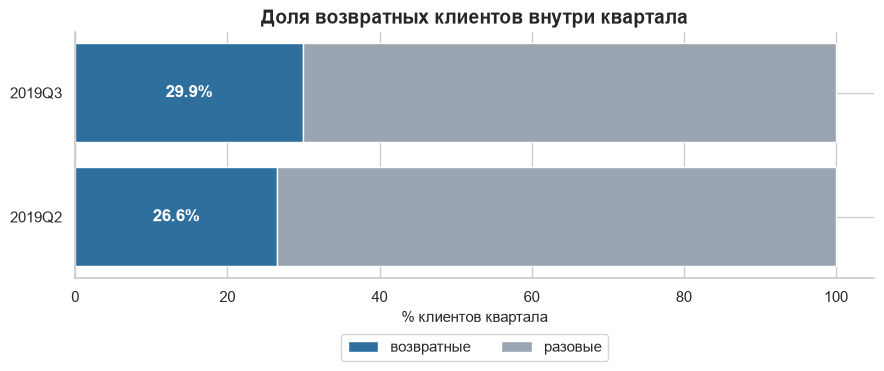

In [44]:
# проверка устойчивости: одни и те же клиенты могут попасть в оба квартала, что нарушает независимость выборок.
# Повторим тест только на клиентах, которые покупали лишь в одном из двух кварталов.
cust_q = orders[orders['quarter'].isin([pd.Period(q, freq='Q') for q in q_avail])].groupby('customer_id')['quarter'].nunique()
only_one = cust_q[cust_q == 1].index
rob = {}
for q in q_avail:
    per_cust = orders[(orders['quarter'] == pd.Period(q, freq='Q')) & orders['customer_id'].isin(only_one)].groupby('customer_id').size()
    rob[q] = (int((per_cust > 1).sum()), len(per_cust))
(rk1, rn1), (rk2, rn2) = rob.values()
z_r, p_r = ztest_proportions(rk1, rn1, rk2, rn2)
print(f'Клиентов, покупавших в обоих кварталах: {num((cust_q == 2).sum())}')
print(f'Без них: доли возвратных {pct(rk1 / rn1, 2)} и {pct(rk2 / rn2, 2)}, z = {z_r:.3f}, p-value {pv(p_r)}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(qtab.index, qtab['доля возвратных'] * 100, color=MAIN, label='возвратные')
ax.barh(qtab.index, (1 - qtab['доля возвратных']) * 100, left=qtab['доля возвратных'] * 100, color=GREY, label='разовые')
for i, v in enumerate(qtab['доля возвратных']):
    ax.text(v * 50, i, f'{v:.1%}', va='center', ha='center', color='white', fontweight='bold')
ax.set_title('Доля возвратных клиентов внутри квартала')
ax.set_xlabel('% клиентов квартала'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

In [45]:
same = p_value >= ALPHA
md(f"""**Вывод.** Доля возвратных клиентов: {', '.join(f'{q} — **{pct(v, 1)}**' for q, v in qtab['доля возвратных'].items())}.
p-value **{pv(p_value)}** {'≥' if same else '<'} 0,05, поэтому **{'нет оснований отвергнуть' if same else 'отвергаем'}** нулевую гипотезу:
{'статистически значимой разницы в доле возвратных клиентов между кварталами нет' if same else 'доли возвратных клиентов во II и III кварталах статистически значимо различаются'}.
Проверка на клиентах, которые покупали только в одном из кварталов (чтобы выборки были независимы), даёт p-value {pv(p_r)} —
вывод {'тот же' if (p_r >= ALPHA) == same else 'другой, поэтому результат основного теста стоит трактовать осторожно'}.""")

**Вывод.** Доля возвратных клиентов: 2019Q2 — **26.6%**, 2019Q3 — **29.9%**.
p-value **0.0838** ≥ 0,05, поэтому **нет оснований отвергнуть** нулевую гипотезу:
статистически значимой разницы в доле возвратных клиентов между кварталами нет.
Проверка на клиентах, которые покупали только в одном из кварталов (чтобы выборки были независимы), даёт p-value 0.1854 —
вывод тот же.

### 5.2. Средний чек в странах с `country_id` = 3, 6 и 24

Средний чек — средняя сумма одного заказа. Сравниваем заказы трёх стран.

- **H₀:** средние чеки в странах 3, 6 и 24 одинаковы.
- **H₁:** хотя бы в одной стране средний чек отличается.

**Выбор теста.** Сначала проверим условия для параметрического теста (ANOVA): нормальность распределения чеков (тест Шапиро — Уилка) и равенство дисперсий (тест Левена). Суммы заказов, как правило, сильно скошены из-за оптовых покупок, поэтому основной тест — непараметрический **Краскел — Уоллис**, а для попарных сравнений — **Манн — Уитни** с поправкой Бонферрони. Поскольку вопрос именно про *средние*, дополнительно проверяем различие средних **t-тестом Уэлча** (не требует равенства дисперсий, а при больших выборках устойчив к ненормальности благодаря ЦПТ) и строим бутстреп-интервалы для средних.

In [46]:
COUNTRIES = [3, 6, 24]
cid = orders['country_id']
target = [str(c) for c in COUNTRIES] if not pd.api.types.is_numeric_dtype(cid) else COUNTRIES
checks = {c: orders.loc[cid == t, 'revenue'].values for c, t in zip(COUNTRIES, target)}

desc = pd.DataFrame({c: {'заказов': len(v), 'клиентов': orders.loc[cid == t, 'customer_id'].nunique(),
                         'средний чек': np.mean(v) if len(v) else np.nan, 'медиана': np.median(v) if len(v) else np.nan,
                         'ст. отклонение': np.std(v, ddof=1) if len(v) > 1 else np.nan,
                         'асимметрия': stats.skew(v) if len(v) > 2 else np.nan}
                     for (c, v), t in zip(checks.items(), target)}).T
desc.index = [f'страна {c}' for c in desc.index]
display(desc.style.format({'заказов': '{:,.0f}', 'клиентов': '{:,.0f}', 'средний чек': '{:,.1f}', 'медиана': '{:,.1f}',
                           'ст. отклонение': '{:,.1f}', 'асимметрия': '{:.2f}'}))
if (desc['заказов'] < 20).any():
    print('Внимание: в одной из стран мало заказов — результаты тестов для неё ненадёжны')

,заказов,клиентов,средний чек,медиана,ст. отклонение,асимметрия
страна 3,40,19,"27,413.2","23,533.0","17,195.2",1.05
страна 6,172,71,"34,179.6","21,353.5","48,695.5",6.58
страна 24,11,5,"44,151.7","23,875.0","59,729.1",1.76


Внимание: в одной из стран мало заказов — результаты тестов для неё ненадёжны


In [47]:
valid = {c: v for c, v in checks.items() if len(v) >= 3}
rng = np.random.default_rng(RANDOM_STATE)

print('Нормальность (Шапиро — Уилк, выборка до 5000 заказов):')
for c, v in valid.items():
    sample = v if len(v) <= 5000 else rng.choice(v, 5000, replace=False)
    print(f'  страна {c}: p-value = {stats.shapiro(sample).pvalue:.2e}')
lev = stats.levene(*valid.values(), center='median')
print(f'Равенство дисперсий (Левен): p-value = {lev.pvalue:.4f}')

kw = stats.kruskal(*valid.values())
print(f'\nКраскел — Уоллис: H = {kw.statistic:.2f}, p-value {pv(kw.pvalue)}')
S['h2_p'] = kw.pvalue

pairs_res = []
n_cmp = len(list(itertools.combinations(valid, 2)))
for a, b in itertools.combinations(valid, 2):
    mw = stats.mannwhitneyu(valid[a], valid[b], alternative='two-sided')
    tt = stats.ttest_ind(valid[a], valid[b], equal_var=False)
    pairs_res.append({'пара': f'{a} vs {b}',
                      'средний чек A': valid[a].mean(), 'средний чек B': valid[b].mean(),
                      'p Манн — Уитни (Бонферрони)': min(mw.pvalue * n_cmp, 1),
                      'p t-тест Уэлча (Бонферрони)': min(tt.pvalue * n_cmp, 1)})
pairs_res = pd.DataFrame(pairs_res).set_index('пара')
pairs_res['различие значимо'] = np.where((pairs_res['p Манн — Уитни (Бонферрони)'] < ALPHA), 'да', 'нет')
display(pairs_res.style.format({'средний чек A': '{:,.1f}', 'средний чек B': '{:,.1f}',
                                'p Манн — Уитни (Бонферрони)': '{:.4f}', 'p t-тест Уэлча (Бонферрони)': '{:.4f}'}))

Нормальность (Шапиро — Уилк, выборка до 5000 заказов):
  страна 3: p-value = 1.77e-02
  страна 6: p-value = 5.01e-22
  страна 24: p-value = 7.82e-05
Равенство дисперсий (Левен): p-value = 0.2900

Краскел — Уоллис: H = 0.26, p-value 0.8786


,средний чек A,средний чек B,p Манн — Уитни (Бонферрони),p t-тест Уэлча (Бонферрони),различие значимо
пара,,,,,
3 vs 6,"27,413.2","34,179.6",1.0000,0.4297,нет
3 vs 24,"27,413.2","44,151.7",1.0000,1.0000,нет
6 vs 24,"34,179.6","44,151.7",1.0000,1.0000,нет


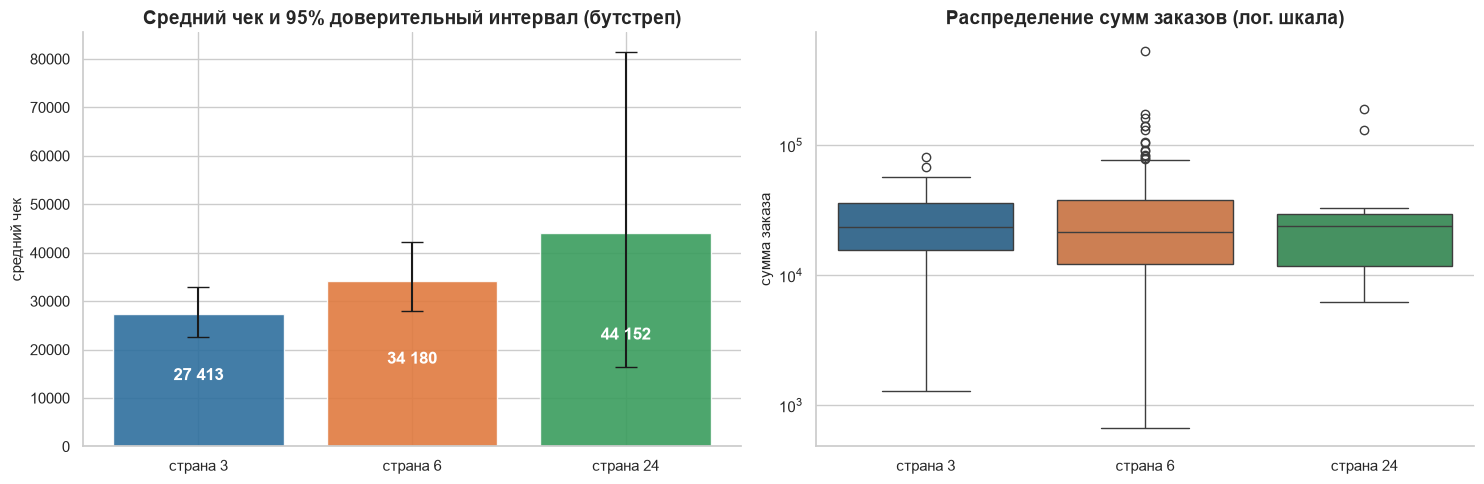

In [48]:
def bootstrap_ci(values, n_boot=2000, seed=RANDOM_STATE):
    """95% доверительный интервал для среднего методом бутстрепа."""
    r = np.random.default_rng(seed)
    means = np.array([r.choice(values, len(values), replace=True).mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

ci = {c: bootstrap_ci(v) for c, v in valid.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels_c = [f'страна {c}' for c in valid]
means = [v.mean() for v in valid.values()]
err = np.array([[m - ci[c][0], ci[c][1] - m] for c, m in zip(valid, means)]).T
axes[0].bar(labels_c, means, yerr=err, capsize=8, color=[MAIN, ACCENT, GOOD][:len(valid)], alpha=0.9)
for i, m in enumerate(means):
    axes[0].text(i, m / 2, num(m), ha='center', color='white', fontweight='bold')
axes[0].set_title('Средний чек и 95% доверительный интервал (бутстреп)')
axes[0].set_ylabel('средний чек')

box = pd.DataFrame({'страна': np.repeat(labels_c, [len(v) for v in valid.values()]),
                    'чек': np.concatenate(list(valid.values()))})
sns.boxplot(data=box, x='страна', y='чек', palette=[MAIN, ACCENT, GOOD][:len(valid)], ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Распределение сумм заказов (лог. шкала)')
axes[1].set_xlabel(''); axes[1].set_ylabel('сумма заказа')
plt.tight_layout()
plt.show()

In [49]:
diff = kw.pvalue < ALPHA
sig_pairs = pairs_res.index[pairs_res['различие значимо'] == 'да'].tolist()
welch_pairs = pairs_res.index[pairs_res['p t-тест Уэлча (Бонферрони)'] < ALPHA].tolist()
welch_n = len(welch_pairs)
md(f"""**Вывод.** Распределения сумм заказов не нормальные (p-value теста Шапиро — Уилка близко к нулю) и сильно скошены вправо,
поэтому основной вывод делаем по непараметрическому тесту Краскела — Уоллиса: p-value **{pv(kw.pvalue)}** {'<' if diff else '≥'} 0,05 —
**{'отвергаем' if diff else 'нет оснований отвергнуть'}** нулевую гипотезу.
{('Чеки различаются; попарно значимы различия в парах: ' + ', '.join(sig_pairs) + '.') if sig_pairs else 'Попарные сравнения тоже не выявили значимых различий.'}
Средние чеки: {', '.join(f'страна {c} — {num(v.mean())}' for c, v in valid.items())}.
t-тест Уэлча, который сравнивает именно средние, показывает значимые различия в {welch_n} из {len(pairs_res)} пар{(' (' + ', '.join(welch_pairs) + ')') if welch_pairs else ''}.
Средние сильно зависят от редких крупных оптовых заказов (см. широкие доверительные интервалы на графике), поэтому вывод по типичным заказам (тест Краскела — Уоллиса и Манна — Уитни) надёжнее.""")

**Вывод.** Распределения сумм заказов не нормальные (p-value теста Шапиро — Уилка близко к нулю) и сильно скошены вправо,
поэтому основной вывод делаем по непараметрическому тесту Краскела — Уоллиса: p-value **0.8786** ≥ 0,05 —
**нет оснований отвергнуть** нулевую гипотезу.
Попарные сравнения тоже не выявили значимых различий.
Средние чеки: страна 3 — 27 413, страна 6 — 34 180, страна 24 — 44 152.
t-тест Уэлча, который сравнивает именно средние, показывает значимые различия в 0 из 3 пар.
Средние сильно зависят от редких крупных оптовых заказов (см. широкие доверительные интервалы на графике), поэтому вывод по типичным заказам (тест Краскела — Уоллиса и Манна — Уитни) надёжнее.

### 5.3. Собственная гипотеза: крупный первый заказ — признак будущего постоянного клиента?

Бизнесу важно уже по первой покупке понимать, стоит ли вкладываться в удержание клиента. Проверим, отличается ли **сумма первого заказа** у клиентов, которые потом вернулись, от суммы заказа у тех, кто купил один раз. Сравниваем именно первые заказы, чтобы число заказов не влияло на результат.

- **H₀:** суммы первого заказа у будущих возвратных и у разовых клиентов не различаются.
- **H₁:** суммы первого заказа различаются.

**Тест:** Манн — Уитни (распределения сумм скошены), для средних — t-тест Уэлча.

,клиентов,средняя сумма 1-го заказа,медиана
возвратные,"1,476","28,006.3","20,013.0"
разовые,"1,435","23,317.6","16,517.0"


Манн — Уитни: p-value < 0.0001; t-тест Уэлча: p-value 0.0004


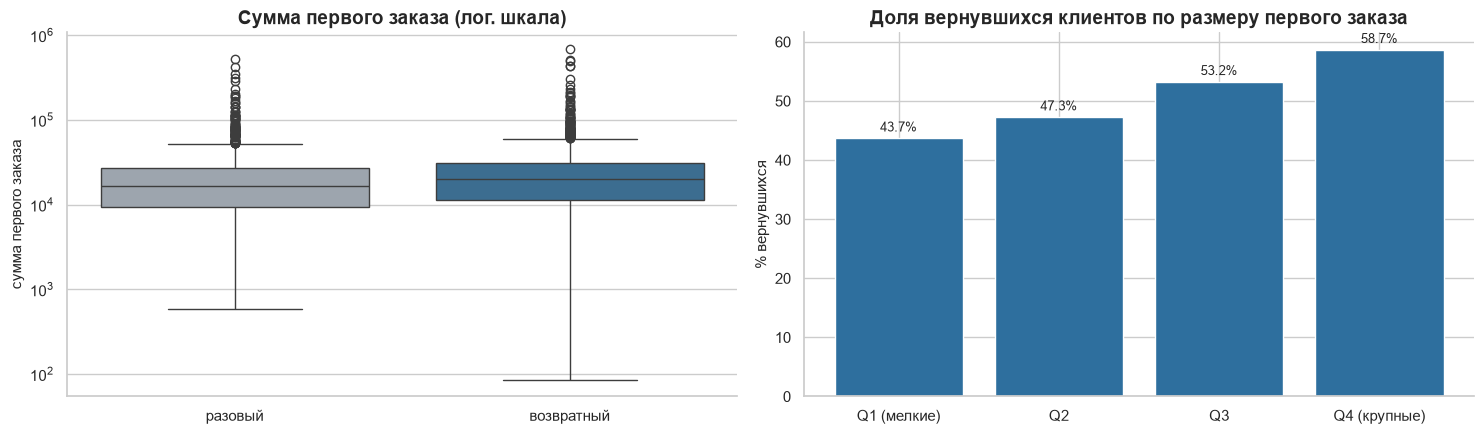

In [50]:
first_orders = orders.sort_values('order_date').drop_duplicates('customer_id')
first_orders = first_orders.merge(profile[['тип клиента']], left_on='customer_id', right_index=True)
a = first_orders.loc[first_orders['тип клиента'] == 'возвратный', 'revenue']
b = first_orders.loc[first_orders['тип клиента'] == 'разовый', 'revenue']

mw = stats.mannwhitneyu(a, b, alternative='two-sided')
tt = stats.ttest_ind(a, b, equal_var=False)
S['h3_p'] = mw.pvalue
display(pd.DataFrame({'клиентов': [len(a), len(b)], 'средняя сумма 1-го заказа': [a.mean(), b.mean()],
                      'медиана': [a.median(), b.median()]}, index=['возвратные', 'разовые'])
        .style.format({'клиентов': '{:,.0f}', 'средняя сумма 1-го заказа': '{:,.1f}', 'медиана': '{:,.1f}'}))
print(f'Манн — Уитни: p-value {pv(mw.pvalue)}; t-тест Уэлча: p-value {pv(tt.pvalue)}')

# доля вернувшихся в зависимости от размера первого заказа
first_orders['квартиль 1-го заказа'] = pd.qcut(first_orders['revenue'], 4, labels=['Q1 (мелкие)', 'Q2', 'Q3', 'Q4 (крупные)'])
ret_by_q = first_orders.groupby('квартиль 1-го заказа', observed=True)['тип клиента'].apply(lambda s: (s == 'возвратный').mean())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=first_orders, x='тип клиента', y='revenue', order=['разовый', 'возвратный'],
            palette={'разовый': GREY, 'возвратный': MAIN}, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Сумма первого заказа (лог. шкала)')
axes[0].set_xlabel(''); axes[0].set_ylabel('сумма первого заказа')
axes[1].bar(ret_by_q.index.astype(str), ret_by_q.values * 100, color=MAIN)
annotate_bars(axes[1], '{:.1f}%')
axes[1].set_title('Доля вернувшихся клиентов по размеру первого заказа')
axes[1].set_ylabel('% вернувшихся')
plt.tight_layout()
plt.show()

In [51]:
d3 = mw.pvalue < ALPHA
md(f"""**Вывод.** Медианная сумма первого заказа у будущих возвратных клиентов — **{num(a.median())}**, у разовых — **{num(b.median())}**.
p-value **{pv(mw.pvalue)}** {'<' if d3 else '≥'} 0,05 — **{'отвергаем' if d3 else 'нет оснований отвергнуть'}** нулевую гипотезу.
{'Размер первого заказа связан с вероятностью вернуться: ' if d3 else 'Размер первого заказа слабо связан с возвратом: '}
среди клиентов с самыми мелкими первыми заказами вернулись **{pct(ret_by_q.iloc[0])}**, с самыми крупными — **{pct(ret_by_q.iloc[-1])}**.
{'Практический вывод: клиентов с крупным первым заказом стоит сразу передавать в программу удержания (это потенциальные оптовики), а для мелких — стимулировать увеличение второго заказа.' if d3 else 'Практический вывод: удерживать нужно всех новых клиентов, а не только крупных — размер первой покупки не предсказывает возврат.'}""")

**Вывод.** Медианная сумма первого заказа у будущих возвратных клиентов — **20 013**, у разовых — **16 517**.
p-value **< 0.0001** < 0,05 — **отвергаем** нулевую гипотезу.
Размер первого заказа связан с вероятностью вернуться: 
среди клиентов с самыми мелкими первыми заказами вернулись **43.7%**, с самыми крупными — **58.7%**.
Практический вывод: клиентов с крупным первым заказом стоит сразу передавать в программу удержания (это потенциальные оптовики), а для мелких — стимулировать увеличение второго заказа.

## Шаг 7. Дополнительное исследование: какие товары покупают вместе

*(Шаг выполнен перед общим выводом, чтобы учесть его результаты.)*

Для каждой пары товаров считаем, в скольких заказах они встретились вместе. Чтобы оценить, насколько связь неслучайна, считаем:
- **поддержку (support)** — долю заказов, в которых есть оба товара;
- **уверенность (confidence A→B)** — долю заказов с товаром A, где есть и товар B;
- **лифт (lift)** — во сколько раз чаще пара встречается вместе, чем если бы товары покупали независимо (lift > 1 — товары «тянут» друг друга).

Чтобы расчёт был быстрым, берём 300 самых популярных товаров — именно для них рекомендации имеют практический смысл.

In [52]:
TOP_N = 300
n_orders = df['order_id'].nunique()
prod_orders = df.groupby('entry_id')['order_id'].nunique()
top_ids = set(prod_orders.nlargest(TOP_N).index)

baskets = df[df['entry_id'].isin(top_ids)].groupby('order_id')['entry_id'].agg(lambda s: sorted(set(s)))
pair_counts = Counter()
for items in baskets:
    if len(items) > 1:
        pair_counts.update(itertools.combinations(items, 2))

pairs_df = pd.DataFrame([(a, b, c) for (a, b), c in pair_counts.items()], columns=['A', 'B', 'заказов вместе'])
pairs_df['support'] = pairs_df['заказов вместе'] / n_orders
pairs_df['conf A→B'] = pairs_df['заказов вместе'] / pairs_df['A'].map(prod_orders)
pairs_df['conf B→A'] = pairs_df['заказов вместе'] / pairs_df['B'].map(prod_orders)
pairs_df['lift'] = pairs_df['support'] / (pairs_df['A'].map(prod_orders) / n_orders * pairs_df['B'].map(prod_orders) / n_orders)
pairs_df['товар A'] = pairs_df['A'].map(names)
pairs_df['товар B'] = pairs_df['B'].map(names)

top_pairs = pairs_df.sort_values('заказов вместе', ascending=False).head(15)
display(top_pairs[['товар A', 'товар B', 'заказов вместе', 'support', 'conf A→B', 'conf B→A', 'lift']]
        .reset_index(drop=True)
        .style.format({'заказов вместе': '{:,.0f}', 'support': '{:.2%}', 'conf A→B': '{:.1%}', 'conf B→A': '{:.1%}', 'lift': '{:.1f}'}))

,товар A,товар B,заказов вместе,support,conf A→B,conf B→A,lift
0,большая сумка красного цвета Retrospot,большая сумка розового цвета в горошек,339,4.25%,39.1%,66.2%,6.1
1,Зеленая чашка и блюдце в стиле регентства,"Розы Регентства, чашка и блюдце",318,3.98%,75.5%,74.5%,14.1
2,большая сумка красного цвета Retrospot,гигантская сумка для хранения Suki,317,3.97%,36.6%,63.1%,5.8
3,сумка для обеда дизайн Суки,сумка для обеда красная Retrospot,275,3.44%,51.8%,42.0%,6.3
4,Зеленая чашка и блюдце в стиле регентства,Розовая чашка и блюдце в стиле регентства,255,3.19%,60.6%,82.0%,15.5
5,сумка для обеда в розовый горошек,сумка для обеда красная Retrospot,254,3.18%,58.0%,38.8%,7.1
6,большая сумка красного цвета Retrospot,сумка для обеда красная Retrospot,249,3.12%,28.8%,38.0%,3.5
7,Розовая чашка и блюдце в стиле регентства,"Розы Регентства, чашка и блюдце",246,3.08%,79.1%,57.6%,14.8
8,большая сумка красного цвета Retrospot,большой пакет яблок,237,2.97%,27.4%,58.4%,5.4
9,"Сумка для обеда, дизайн космического мальчика",сумка для обеда красная Retrospot,236,2.96%,50.1%,36.0%,6.1


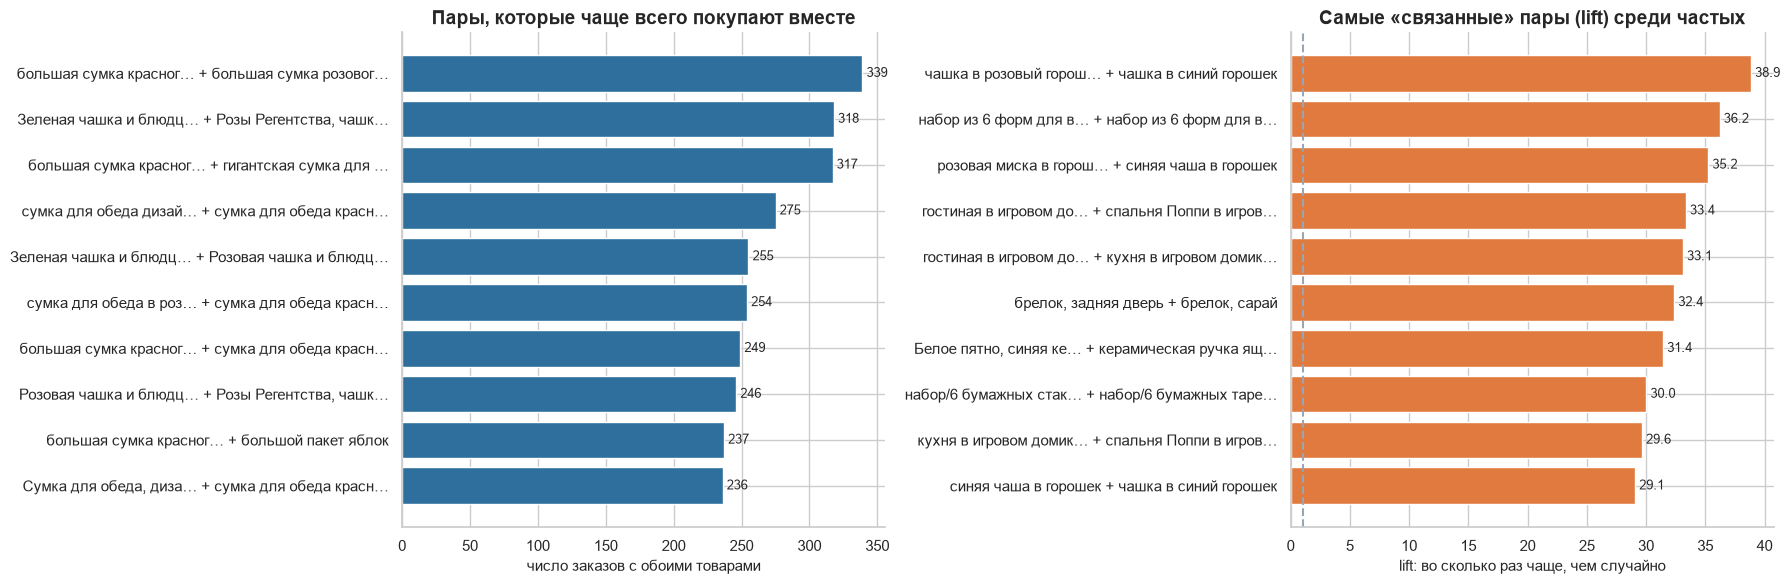

In [53]:
strong = pairs_df[pairs_df['заказов вместе'] >= max(20, pairs_df['заказов вместе'].quantile(0.9))].sort_values('lift', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
tp = top_pairs.head(10).iloc[::-1]
axes[0].barh([f'{short(a, 22)} + {short(b, 22)}' for a, b in zip(tp['товар A'], tp['товар B'])], tp['заказов вместе'], color=MAIN)
annotate_bars(axes[0], horizontal=True)
axes[0].set_title('Пары, которые чаще всего покупают вместе')
axes[0].set_xlabel('число заказов с обоими товарами')

sp = strong.iloc[::-1]
axes[1].barh([f'{short(a, 22)} + {short(b, 22)}' for a, b in zip(sp['товар A'], sp['товар B'])], sp['lift'], color=ACCENT)
annotate_bars(axes[1], '{:.1f}', horizontal=True)
axes[1].axvline(1, color=GREY, ls='--')
axes[1].set_title('Самые «связанные» пары (lift) среди частых')
axes[1].set_xlabel('lift: во сколько раз чаще, чем случайно')
plt.tight_layout()
plt.show()

In [54]:
best = top_pairs.iloc[0]
clust_of = df.groupby('entry_id')['name_clust'].first()
same_cl = int((top_pairs['A'].map(clust_of) == top_pairs['B'].map(clust_of)).sum())
S['same_cl'] = same_cl
S['pair_best'] = f"«{best['товар A']}» + «{best['товар B']}»"
md(f"""**Вывод.** Чаще всего вместе покупают {S['pair_best']} — **{num(best['заказов вместе'])}** заказов,
причём {pct(best['conf A→B'])} покупателей первого товара берут и второй (lift = {best['lift']:.1f}).
Из 15 самых частых пар **{same_cl}** состоят из товаров одной группы `name_clust` (похожих по названию){' — клиенты собирают наборы из одной линейки' if same_cl >= 8 else ', остальные — сочетания разных групп, то есть клиенты дополняют покупку сопутствующими товарами'}.
**Рекомендации:** продавать такие пары комплектами со скидкой, показывать блок «С этим товаром покупают» на карточке товара и в корзине,
использовать пары с высоким lift для персональных подборок лояльным клиентам и в письмах «Новичкам».""")

**Вывод.** Чаще всего вместе покупают «большая сумка красного цвета Retrospot» + «большая сумка розового цвета в горошек» — **339** заказов,
причём 39.1% покупателей первого товара берут и второй (lift = 6.1).
Из 15 самых частых пар **2** состоят из товаров одной группы `name_clust` (похожих по названию), остальные — сочетания разных групп, то есть клиенты дополняют покупку сопутствующими товарами.
**Рекомендации:** продавать такие пары комплектами со скидкой, показывать блок «С этим товаром покупают» на карточке товара и в корзине,
использовать пары с высоким lift для персональных подборок лояльным клиентам и в письмах «Новичкам».

## Шаг 6. Общий вывод

In [55]:
h1_txt = 'не различаются' if S['h1_p'] >= ALPHA else 'различаются'
h2_txt = 'различаются' if S['h2_p'] < ALPHA else 'не различаются'
h3_txt = 'связан' if S['h3_p'] < ALPHA else 'не связан'
md(f"""### Что сделано
1. Данные о продажах объединены со справочником товаров. Восстановлены номера клиентов по заказу, удалены дубликаты, строки без клиента,
   отменённые покупки, возвраты, служебные записи (доставка, комиссии) и экстремальные значения. Для анализа выбран период с полными данными — **{S['period']}**.
2. Рассчитаны метрики активности, выручки, «липкости», составлены профили клиентов, проведена RFM-сегментация, проверены три гипотезы.

### Главные результаты
- **Покупательская активность цикличная.** Заказы приходят в рабочее время с пиком **{S['peak_hours']}**, лучший день — **{S['best_weekday']}**{('; в ' + ', '.join(S['zero_days']) + ' продаж нет') if S['zero_days'] else ''}. Похоже на поведение оптовых и корпоративных покупателей.
- **Сезонность.** Больше всего покупателей — в **{S['best_month']}**; в сильные месяцы выручка растёт за счёт числа покупателей, а не чека.
  Для вывода об устойчивой сезонности нужна история больше одного года.
- **Липкость {'низкая — это нормально для подарков' if max(S['sticky'].values()) < 0.2 else 'высокая для магазина подарков'}:** sticky factor {', '.join(f'{k} — {pct(v)}' for k, v in S['sticky'].items())}. Покупки делаются по поводу.
- **Возвратные клиенты — основа выручки:** их {pct(S['returning_share'])}, а приносят они **{pct(S['returning_rev_share'])}** выручки.
- **RFM:** «Чемпионы» и «Лояльные» — {pct(S['seg_top_cust'])} клиентов и **{pct(S['seg_top_rev'])}** выручки; «Под угрозой ухода» держат {pct(S['seg_risk_rev'])} выручки;
  клиенты с одной покупкой — {pct(S['seg_one_cust'])} базы, но лишь {pct(S['seg_one_rev'])} выручки.
- **Гипотезы:** доли возвратных клиентов во II и III кварталах 2019 года **{h1_txt}** (p-value {pv(S['h1_p'])});
  чеки в странах 3, 6 и 24 **{h2_txt}** (p-value {pv(S['h2_p'])}); размер первого заказа **{h3_txt}** с тем, вернётся ли клиент (p-value {pv(S['h3_p'])}).
- **Совместные покупки:** самая частая пара — {S['pair_best']}; из 15 самых частых пар {S['same_cl']} — товары одной группы по названию.

### Рекомендации бизнесу
1. **Удерживать после первой покупки** — главный рычаг роста: приветственная серия и предложение на второй заказ для «Новичков».
2. **Срочно возвращать «Под угрозой ухода»** персональными предложениями — на них приходится заметная доля выручки.
3. **Беречь ядро** («Чемпионы», «Лояльные»): программа лояльности, персональный менеджер для оптовиков, ранний доступ к новинкам вместо скидок.
4. **Комплекты и допродажи** на основе пар товаров, которые покупают вместе.
5. **Время коммуникаций:** рассылки — утром в будни, перед пиком заказов; сезонные кампании запускать заранее, до месяцев максимального спроса.
6. **Качество данных:** отмечать отмены и служебные операции отдельным полем, не терять номер клиента в заказах — это упростит аналитику и сделает метрики точнее.""")

### Что сделано
1. Данные о продажах объединены со справочником товаров. Восстановлены номера клиентов по заказу, удалены дубликаты, строки без клиента,
   отменённые покупки, возвраты, служебные записи (доставка, комиссии) и экстремальные значения. Для анализа выбран период с полными данными — **дек 2018 — дек 2019**.
2. Рассчитаны метрики активности, выручки, «липкости», составлены профили клиентов, проведена RFM-сегментация, проверены три гипотезы.

### Главные результаты
- **Покупательская активность цикличная.** Заказы приходят в рабочее время с пиком **11:00–14:00**, лучший день — **Вс**; в Вт продаж нет. Похоже на поведение оптовых и корпоративных покупателей.
- **Сезонность.** Больше всего покупателей — в **ноя 2019**; в сильные месяцы выручка растёт за счёт числа покупателей, а не чека.
  Для вывода об устойчивой сезонности нужна история больше одного года.
- **Липкость низкая — это нормально для подарков:** sticky factor 2019Q2 — 10.9%, 2019Q3 — 10.6%. Покупки делаются по поводу.
- **Возвратные клиенты — основа выручки:** их 50.7%, а приносят они **87.0%** выручки.
- **RFM:** «Чемпионы» и «Лояльные» — 42.7% клиентов и **81.6%** выручки; «Под угрозой ухода» держат 5.4% выручки;
  клиенты с одной покупкой — 49.3% базы, но лишь 13.0% выручки.
- **Гипотезы:** доли возвратных клиентов во II и III кварталах 2019 года **не различаются** (p-value 0.0838);
  чеки в странах 3, 6 и 24 **не различаются** (p-value 0.8786); размер первого заказа **связан** с тем, вернётся ли клиент (p-value < 0.0001).
- **Совместные покупки:** самая частая пара — «большая сумка красного цвета Retrospot» + «большая сумка розового цвета в горошек»; из 15 самых частых пар 2 — товары одной группы по названию.

### Рекомендации бизнесу
1. **Удерживать после первой покупки** — главный рычаг роста: приветственная серия и предложение на второй заказ для «Новичков».
2. **Срочно возвращать «Под угрозой ухода»** персональными предложениями — на них приходится заметная доля выручки.
3. **Беречь ядро** («Чемпионы», «Лояльные»): программа лояльности, персональный менеджер для оптовиков, ранний доступ к новинкам вместо скидок.
4. **Комплекты и допродажи** на основе пар товаров, которые покупают вместе.
5. **Время коммуникаций:** рассылки — утром в будни, перед пиком заказов; сезонные кампании запускать заранее, до месяцев максимального спроса.
6. **Качество данных:** отмечать отмены и служебные операции отдельным полем, не терять номер клиента в заказах — это упростит аналитику и сделает метрики точнее.